# MAGNET: Multi-scale Attention-based Graph Network with Ensemble Transfer Learning
# for Breast Cancer Histopathology Classification

## 1. Environment Setup

In [1]:
import subprocess, sys

def pip_install(pkg):
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', pkg])

for pkg, mod in [('timm','timm'), ('statsmodels','statsmodels'), ('scipy','scipy')]:
    try:
        __import__(mod)
    except ImportError:
        pip_install(pkg)

print('All packages ready.')

All packages ready.


In [2]:
import os, sys, re, random, json, time, copy, warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image
from torchvision import transforms
import cv2
import scipy.stats as st
from statsmodels.stats.contingency_tables import mcnemar as mcnemar_test_fn
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, roc_auc_score, roc_curve, classification_report
)

import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
import timm
from tqdm import tqdm

def set_seed(seed=42):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    if torch.cuda.is_available(): torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

set_seed(42)

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Device : {device}')
if device.type == 'cuda':
    print(f'GPU    : {torch.cuda.get_device_name(0)}')
    print(f'VRAM   : {torch.cuda.get_device_properties(0).total_memory/1024**2:.0f} MB')

for d in ['results','checkpoints','plots']:
    os.makedirs(d, exist_ok=True)
print('Setup complete.')

# ── CPU-safe autocast helper ───────────────────────────────────────────────
import contextlib

def autocast_ctx():
    """
    Returns torch.amp.autocast for CUDA, or a no-op context on CPU.
    Prevents 'autocast not supported on CPU' errors if GPU is unavailable.
    """
    if device.type == 'cuda':
        return torch.amp.autocast(device_type='cuda')
    return contextlib.nullcontext()

Device : cuda
GPU    : NVIDIA GeForce GTX 1650
VRAM   : 4096 MB
Setup complete.


## 2. Configuration

In [3]:
# ── Dataset path ──────────────────────────────────────────────────────────────
DATA_ROOT = 'data/BreaKHis_v1/BreaKHis_v1/histology_slides/breast'

# ── Hardware knobs (GTX 1650 4 GB) ───────────────────────────────────────────
BATCH_SIZE      = 4      # keep at 4; 8 will OOM
NUM_WORKERS     = 0      # MUST be 0 on Windows + Jupyter (multiprocessing deadlock)
IMG_SIZE        = 224
FEAT_DIM        = 512
MAGNIFICATIONS  = ['40X', '100X', '200X', '400X']

# ── Training hyperparameters ──────────────────────────────────────────────────
EPOCHS          = 50
LR              = 1e-4
WEIGHT_DECAY    = 1e-4   # increased from 1e-5 — stronger regularisation on 82 patients
EARLY_STOP      = 12
LABEL_SMOOTHING = 0.1    # reduces overconfident predictions on small dataset

# ── Cross-validation ─────────────────────────────────────────────────────────
N_FOLDS     = 5
KF_EPOCHS   = 30         # shorter per fold (5 folds × 30 epochs ≈ full training)
KF_PATIENCE = 8

# ── Backbones ─────────────────────────────────────────────────────────────────
BACKBONES = {
    '40X' : 'mobilenetv3_large_100',
    '100X': 'efficientnet_b0',
    '200X': 'resnet34',
    '400X': 'mobilenetv3_small_100',
}
BACKBONE_OUT_DIM = {
    '40X' : 1280,
    '100X': 1280,
    '200X': 512,
    '400X': 1024,
}

def _safe_name(s):
    """Sanitise string for use as filename (removes / \\ : etc.)."""
    return re.sub(r'[^\w\-]', '_', s)

print('Config loaded.')

Config loaded.


## 3. Data Preparation

### 3.1 Stain Normalisation (Macenko, simplified)

In [4]:
def macenko_norm(img_pil: Image.Image) -> Image.Image:
    """
    OD-space colour normalisation (simplified Macenko).
    For exact Macenko: pip install staintools
    """
    img = np.array(img_pil, dtype=np.float32)
    img = np.clip(img, 1, 255)
    OD  = -np.log(img / 255.0)
    for c in range(3):
        m = OD[..., c].mean()
        s = OD[..., c].std() + 1e-6
        OD[..., c] = (OD[..., c] - m) / s * 0.3 + 0.4
    img_norm = np.exp(-OD) * 255.0
    return Image.fromarray(np.clip(img_norm, 0, 255).astype(np.uint8))

print('Stain normaliser defined.')

Stain normaliser defined.


### 3.2 Patient Index + Stratified Splits

In [5]:
BENIGN_SUBS    = ['adenosis','fibroadenoma','phyllodes_tumor','tubular_adenoma']
MALIGNANT_SUBS = ['ductal_carcinoma','lobular_carcinoma','mucinous_carcinoma','papillary_carcinoma']
ALL_SUBS       = BENIGN_SUBS + MALIGNANT_SUBS
SUB2IDX        = {s: i for i, s in enumerate(ALL_SUBS)}

def collect_patient_info(root_dir):
    """
    Supports both BreakHis folder layouts:
      Layout A (common): breast/benign/SOB/adenosis/<patient>/<mag>/*.png
      Layout B (some downloads): breast/benign/adenosis/<patient>/<mag>/*.png
    """
    patients = {}
    for cls_name, binary, subs in [
            ('benign', 0, BENIGN_SUBS), ('malignant', 1, MALIGNANT_SUBS)]:
        cls_path = os.path.join(root_dir, cls_name)
        if not os.path.isdir(cls_path):
            continue
        # Try SOB subdir first (Layout A), then direct (Layout B)
        sob_path = os.path.join(cls_path, 'SOB')
        search_root = sob_path if os.path.isdir(sob_path) else cls_path

        for sub in subs:
            sub_path = os.path.join(search_root, sub)
            if not os.path.isdir(sub_path):
                continue
            for pat in os.listdir(sub_path):
                pat_path = os.path.join(sub_path, pat)
                if not os.path.isdir(pat_path):
                    continue
                if pat not in patients:
                    patients[pat] = {
                        'binary' : binary,
                        'subtype': SUB2IDX[sub],
                        'paths'  : {m: [] for m in MAGNIFICATIONS}
                    }
                for mag in MAGNIFICATIONS:
                    mag_path = os.path.join(pat_path, mag)
                    if os.path.isdir(mag_path):
                        for fname in os.listdir(mag_path):
                            if fname.lower().endswith('.png'):
                                patients[pat]['paths'][mag].append(
                                    os.path.join(mag_path, fname))
    return patients


# ── Safety: fail loudly if dataset not found ──────────────────────────────────
if not os.path.isdir(DATA_ROOT):
    raise FileNotFoundError(
        f'BreakHis dataset not found at:\n  {DATA_ROOT}\n'
        'Download from: https://web.inf.ufpr.br/vri/databases/'
        'breast-cancer-histopathological-database-breakhis/\n'
        'Then update DATA_ROOT in the config cell.'
    )

patient_info = collect_patient_info(DATA_ROOT)

if len(patient_info) == 0:
    raise RuntimeError(
        f'No patients found under {DATA_ROOT}.\n'
        'Check that the folder structure matches:\n'
        '  breast/benign/SOB/<subtype>/<patient_id>/<magnification>/*.png\n'
        'or:\n'
        '  breast/benign/<subtype>/<patient_id>/<magnification>/*.png'
    )

all_patients = list(patient_info.keys())
pat_labels   = [patient_info[p]['binary'] for p in all_patients]

# ── Dataset statistics ────────────────────────────────────────────────────────
n_benign    = sum(1 for p in all_patients if patient_info[p]['binary'] == 0)
n_malignant = len(all_patients) - n_benign
total_imgs  = sum(len(v) for p in all_patients
                  for v in patient_info[p]['paths'].values())

print(f'Total patients : {len(all_patients)}')
print(f'  Benign       : {n_benign}  ({100*n_benign/len(all_patients):.1f}%)')
print(f'  Malignant    : {n_malignant}  ({100*n_malignant/len(all_patients):.1f}%)')
print(f'Total images   : {total_imgs}')

from collections import Counter
sub_counts = Counter(patient_info[p]['subtype'] for p in all_patients)
print('\nSubtype distribution:')
for idx, name in enumerate(ALL_SUBS):
    print(f'  {name:<25}: {sub_counts.get(idx, 0)} patients')

# Check all patients have images at all magnifications
missing = [(p, mag) for p in all_patients for mag in MAGNIFICATIONS
           if not patient_info[p]['paths'][mag]]
if missing:
    print(f'\n⚠ {len(missing)} patient-magnification combinations have no images:')
    for p, m in missing[:5]:
        print(f'  {p} @ {m}')
    if len(missing) > 5:
        print(f'  ... and {len(missing)-5} more')
else:
    print('\n✓ All patients have images at all 4 magnifications.')

# ── Fixed 70/15/15 patient split (for ablation / interpretability cells) ──────
random.seed(42); random.shuffle(all_patients)
n = len(all_patients)
train_patients = all_patients[:int(0.70 * n)]
val_patients   = all_patients[int(0.70 * n):int(0.85 * n)]
test_patients  = all_patients[int(0.85 * n):]
print(f'\nFixed split — Train:{len(train_patients)} Val:{len(val_patients)} Test:{len(test_patients)}')
print('(5-fold CV in Section 7 uses all patients — recommended for publication)')


Total patients : 82
  Benign       : 24  (29.3%)
  Malignant    : 58  (70.7%)
Total images   : 7909

Subtype distribution:
  adenosis                 : 4 patients
  fibroadenoma             : 10 patients
  phyllodes_tumor          : 3 patients
  tubular_adenoma          : 7 patients
  ductal_carcinoma         : 38 patients
  lobular_carcinoma        : 5 patients
  mucinous_carcinoma       : 9 patients
  papillary_carcinoma      : 6 patients

✓ All patients have images at all 4 magnifications.

Fixed split — Train:57 Val:12 Test:13
(5-fold CV in Section 7 uses all patients — recommended for publication)


### 3.3 Dataset & DataLoaders

In [6]:
from torchvision import transforms

class MultiMagDataset(Dataset):
    """Returns one image per magnification for a given patient."""

    def __init__(self, patient_ids, patient_info, transform=None,
                 stain_norm=True, img_size=224):
        self.patient_ids  = patient_ids
        self.patient_info = patient_info
        self.transform    = transform
        self.stain_norm   = stain_norm
        self.img_size     = img_size

    def __len__(self): return len(self.patient_ids)

    def _load(self, path):
        img = Image.open(path).convert('RGB')
        img = img.resize((self.img_size, self.img_size), Image.BILINEAR)
        if self.stain_norm:
            img = macenko_norm(img)
        if self.transform:
            img = self.transform(img)
        return img

    def __getitem__(self, idx):
        pid  = self.patient_ids[idx]
        info = self.patient_info[pid]
        rng  = np.random.default_rng()  # fresh RNG per call — no shared state
        imgs = []
        for mag in MAGNIFICATIONS:
            paths = info['paths'][mag]
            path  = paths[rng.integers(len(paths))] if paths else None
            if path is None:
                imgs.append(torch.zeros(3, self.img_size, self.img_size))
            else:
                imgs.append(self._load(path))
        return (*imgs, int(info['binary']), int(info['subtype']))


# ── Transforms ────────────────────────────────────────────────────────────────
IMG_MEAN = [0.485, 0.456, 0.406]
IMG_STD  = [0.229, 0.224, 0.225]

train_tf = transforms.Compose([
    transforms.RandomHorizontalFlip(),
    transforms.RandomVerticalFlip(),
    transforms.RandomRotation(180),
    transforms.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2, hue=0.05),
    transforms.ToTensor(),
    transforms.Normalize(IMG_MEAN, IMG_STD),
])
val_tf = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(IMG_MEAN, IMG_STD),
])


def make_loader(patients, transform, shuffle, drop_last=None):
    ds = MultiMagDataset(patients, patient_info, transform=transform, img_size=IMG_SIZE)
    dl = drop_last if drop_last is not None else shuffle
    return DataLoader(ds, batch_size=BATCH_SIZE, shuffle=shuffle,
                      num_workers=NUM_WORKERS, pin_memory=False, drop_last=dl)

train_loader = make_loader(train_patients, train_tf, shuffle=True)
val_loader   = make_loader(val_patients,   val_tf,   shuffle=False)
test_loader  = make_loader(test_patients,  val_tf,   shuffle=False)

print(f'Loaders — train={len(train_loader.dataset)} val={len(val_loader.dataset)} test={len(test_loader.dataset)}')
print(f'Batches per train epoch: {len(train_loader)}')

# ── Sanity check: grab one batch and verify shapes ────────────────────────────
print('Sanity check...')
_b = next(iter(train_loader))
print(f'  Batch shapes : {[t.shape for t in _b[:4]]}')
print(f'  Binary labels: {_b[4].tolist()}')
del _b
print('DataLoader OK.')


Loaders — train=57 val=12 test=13
Batches per train epoch: 14
Sanity check...
  Batch shapes : [torch.Size([4, 3, 224, 224]), torch.Size([4, 3, 224, 224]), torch.Size([4, 3, 224, 224]), torch.Size([4, 3, 224, 224])]
  Binary labels: [1, 1, 1, 1]
DataLoader OK.


## 4. Model: MAGNET

### 4.1 Branch Extractor

In [7]:
class BranchExtractor(nn.Module):
    """Pretrained backbone + linear projection to shared feat_dim."""
    def __init__(self, backbone_name, in_dim, out_dim, pretrained=True):
        super().__init__()
        self.backbone = timm.create_model(backbone_name, pretrained=pretrained,
                                          num_classes=0, global_pool='avg')
        self.proj = nn.Sequential(
            nn.Linear(in_dim, out_dim),
            nn.LayerNorm(out_dim),
            nn.GELU(),
        )
    def forward(self, x):
        raw  = self.backbone(x)
        proj = self.proj(raw)
        return raw, proj

print('BranchExtractor defined.')

BranchExtractor defined.


### 4.2 Cross-Magnification Attention Fusion

In [8]:
class CrossMagFusion(nn.Module):
    """Multi-head self-attention across 4 magnification tokens."""
    def __init__(self, feat_dim=512, num_heads=8, dropout=0.1):
        super().__init__()
        assert feat_dim % num_heads == 0
        self.attn      = nn.MultiheadAttention(feat_dim, num_heads, dropout=dropout, batch_first=True)
        self.mag_scale = nn.Parameter(torch.ones(4))
        self.ffn  = nn.Sequential(
            nn.Linear(feat_dim, feat_dim*2), nn.GELU(),
            nn.Dropout(dropout), nn.Linear(feat_dim*2, feat_dim))
        self.norm1 = nn.LayerNorm(feat_dim)
        self.norm2 = nn.LayerNorm(feat_dim)

    def forward(self, feats):
        x = torch.stack(feats, dim=1)                        # [B,4,D]
        attn_out, attn_w = self.attn(x, x, x)
        x = self.norm1(x + attn_out)
        w = F.softmax(self.mag_scale, dim=0)
        fused = (x * w.unsqueeze(0).unsqueeze(-1)).sum(1)    # [B,D]
        fused = self.norm2(fused + self.ffn(fused))
        return fused, attn_w

print('CrossMagFusion defined.')

CrossMagFusion defined.


### 4.3 Batch Graph Network (pure PyTorch)

In [9]:
class SparseGraphConv(nn.Module):
    def __init__(self, in_dim, out_dim):
        super().__init__()
        self.W = nn.Linear(in_dim, out_dim, bias=False)
    def forward(self, h, adj):
        return F.relu(adj @ self.W(h))

class BatchGraphNet(nn.Module):
    """Treats each batch as a graph; edges = cosine similarity > threshold."""
    def __init__(self, feat_dim=512, hidden_dim=256, num_layers=2, threshold=0.5, dropout=0.1):
        super().__init__()
        self.threshold = threshold
        in_d = feat_dim
        layers = []
        for _ in range(num_layers):
            layers.append(SparseGraphConv(in_d, hidden_dim)); in_d = hidden_dim
        self.gcn_layers = nn.ModuleList(layers)
        self.drop    = nn.Dropout(dropout)
        self.readout = nn.Linear(hidden_dim, feat_dim)
        self.norm    = nn.LayerNorm(feat_dim)

    def _adj(self, h):
        norm = F.normalize(h.detach(), p=2, dim=1)
        sim  = torch.mm(norm, norm.t())
        mask = (sim > self.threshold).float()
        mask.fill_diagonal_(1.0)
        deg = mask.sum(1, keepdim=True).clamp(min=1)
        d   = deg.pow(-0.5)
        return mask * d * d.t()

    def forward(self, h):
        adj = self._adj(h)
        out = h
        for layer in self.gcn_layers:
            out = self.drop(layer(out, adj))
        return self.norm(h + self.readout(out))

print('BatchGraphNet defined (pure PyTorch, no DGL).')

BatchGraphNet defined (pure PyTorch, no DGL).


### 4.4 Full MAGNET Model

In [10]:
class MAGNET(nn.Module):
    """
    Multi-scale Attention-based Graph Network with Ensemble Transfer Learning.
    Primary output : binary (benign/malignant) classification.
    Auxiliary output: 8-class subtype (regulariser — not primary claim).
    """
    def __init__(self, feat_dim=FEAT_DIM, num_binary=2, num_subtype=8,
                 pretrained=True, use_gnn=True, use_aux=True):
        super().__init__()
        self.use_gnn = use_gnn
        self.use_aux = use_aux

        self.branches = nn.ModuleDict({
            mag: BranchExtractor(BACKBONES[mag], BACKBONE_OUT_DIM[mag], feat_dim, pretrained)
            for mag in MAGNIFICATIONS
        })
        self.fusion = CrossMagFusion(feat_dim, num_heads=8)
        if use_gnn:
            self.gnn = BatchGraphNet(feat_dim, hidden_dim=256)

        def _head(in_d, out_d):
            return nn.Sequential(
                nn.Linear(in_d, 256), nn.BatchNorm1d(256), nn.GELU(),
                nn.Dropout(0.4), nn.Linear(256, out_d))

        self.binary_head      = _head(feat_dim, num_binary)
        self.subtype_head     = _head(feat_dim, num_subtype)
        self.uncertainty_head = nn.Sequential(
            nn.Linear(feat_dim,128), nn.ReLU(), nn.Dropout(0.5),
            nn.Linear(128,1), nn.Sigmoid())

        if use_aux:
            self.aux_heads = nn.ModuleDict({
                mag: nn.Linear(BACKBONE_OUT_DIM[mag], num_binary)
                for mag in MAGNIFICATIONS
            })

    def forward(self, x40, x100, x200, x400, return_attn=False):
        inputs = {'40X':x40,'100X':x100,'200X':x200,'400X':x400}
        raws, projs, aux_logits = {}, {}, {}
        for mag in MAGNIFICATIONS:
            raw, proj = self.branches[mag](inputs[mag])
            raws[mag]=raw; projs[mag]=proj
            if self.use_aux:
                aux_logits[mag] = self.aux_heads[mag](raw)
        fused, attn_w = self.fusion([projs[m] for m in MAGNIFICATIONS])
        if self.use_gnn:
            fused = self.gnn(fused)
        bl  = self.binary_head(fused)
        sl  = self.subtype_head(fused)
        unc = self.uncertainty_head(fused)
        out = (bl, sl, unc, list(aux_logits.values()) if self.use_aux else [])
        return (*out, attn_w) if return_attn else out

    @torch.no_grad()
    def mc_uncertainty(self, x40, x100, x200, x400, n_passes=20):
        """
        Monte-Carlo Dropout uncertainty.
        Keeps Dropout active; forces all BatchNorm to eval so BN
        uses running stats — safe with batch size 1.
        """
        self.train()
        for m in self.modules():
            if isinstance(m, (nn.BatchNorm1d, nn.BatchNorm2d, nn.BatchNorm3d)):
                m.eval()
        probs = []
        for _ in range(n_passes):
            logits, *_ = self(x40, x100, x200, x400)
            probs.append(F.softmax(logits, dim=1).unsqueeze(0))
        self.eval()
        probs = torch.cat(probs, dim=0)   # [n_passes, B, 2]
        return probs.mean(0), probs.var(0)

print('MAGNET defined.')

MAGNET defined.


### 4.5 Smoke Test

In [11]:
torch.cuda.empty_cache()
_m = MAGNET(pretrained=False).to(device)
total_p = sum(p.numel() for p in _m.parameters())
# Backbone params (pretrained, low LR)
bb_p = sum(p.numel() for mag in MAGNIFICATIONS
           for p in _m.branches[mag].backbone.parameters())
print(f'Total params         : {total_p/1e6:.2f} M')
print(f'Backbone params (low LR) : {bb_p/1e6:.2f} M')
print(f'Trainable head+fusion    : {(total_p-bb_p)/1e6:.2f} M')
_d = [torch.randn(4,3,IMG_SIZE,IMG_SIZE).to(device) for _ in range(4)]
with autocast_ctx():
    bl,sl,unc,aux,aw = _m(*_d, return_attn=True)
print(f'binary:{bl.shape} subtype:{sl.shape} unc:{unc.shape} aux:{[a.shape for a in aux]} attn:{aw.shape}')
if device.type=='cuda':
    print(f'VRAM: {torch.cuda.memory_allocated()/1024**2:.0f} MB')
del _m, _d; torch.cuda.empty_cache()

# Verify MC-Dropout produces different outputs (dropout is live)
_m2 = MAGNET(pretrained=False).to(device)
_x  = [torch.randn(2,3,IMG_SIZE,IMG_SIZE).to(device) for _ in range(4)]
with torch.no_grad():
    m1, _ = _m2.mc_uncertainty(*_x, n_passes=2)
    m2, _ = _m2.mc_uncertainty(*_x, n_passes=2)
# Two independent MC runs should NOT be identical
assert not torch.allclose(m1, m2, atol=1e-6), 'MC-Dropout not active!'
print('MC-Dropout verified active.')
del _m2, _x; torch.cuda.empty_cache()
print('Smoke test passed.')

Total params         : 35.89 M
Backbone params (low LR) : 31.01 M
Trainable head+fusion    : 4.88 M
binary:torch.Size([4, 2]) subtype:torch.Size([4, 8]) unc:torch.Size([4, 1]) aux:[torch.Size([4, 2]), torch.Size([4, 2]), torch.Size([4, 2]), torch.Size([4, 2])] attn:torch.Size([4, 4, 4])
VRAM: 578 MB
MC-Dropout verified active.
Smoke test passed.


## 5. Training Pipeline

### 5.1 Loss Function (with Label Smoothing)

In [12]:
class MAGNETLoss(nn.Module):
    """
    L = α·L_binary + β·L_subtype + γ·L_aux + δ·L_uncertainty
    Label smoothing (ε=0.1) reduces overconfident predictions on small datasets.
    Subtype loss acts as an auxiliary regulariser; not the primary evaluation metric.
    """
    def __init__(self, alpha=1.0, beta=0.5, gamma=0.3, delta=0.05,
                 class_weights=None, label_smoothing=LABEL_SMOOTHING):
        super().__init__()
        self.alpha=alpha; self.beta=beta; self.gamma=gamma; self.delta=delta
        w = class_weights if class_weights is not None else torch.tensor([0.69,0.31])
        self.ce_binary  = nn.CrossEntropyLoss(weight=w, label_smoothing=label_smoothing)
        self.ce_subtype = nn.CrossEntropyLoss(label_smoothing=label_smoothing)
        self.ce_aux     = nn.CrossEntropyLoss(label_smoothing=label_smoothing)
        self.mse        = nn.MSELoss()

    def forward(self, bl, sl, unc, aux, y_bin, y_sub):
        self.ce_binary.weight = self.ce_binary.weight.to(bl.device)
        L_bin = self.ce_binary(bl, y_bin)
        L_sub = self.ce_subtype(sl, y_sub)
        L_aux = torch.tensor(0.0, device=bl.device)
        if aux:
            for a in aux: L_aux = L_aux + self.ce_aux(a, y_bin)
            L_aux = L_aux / len(aux)
        with torch.no_grad():
            conf = F.softmax(bl, dim=1).max(1).values
            t_unc = (1.0 - conf).unsqueeze(1)
        L_unc = self.mse(unc, t_unc)
        total = self.alpha*L_bin + self.beta*L_sub + self.gamma*L_aux + self.delta*L_unc
        return total, {'binary':L_bin.item(),'subtype':L_sub.item(),
                       'aux':L_aux.item(),'unc':L_unc.item()}

print('MAGNETLoss defined.')

MAGNETLoss defined.


### 5.2 Train / Eval Loops

In [13]:
def make_scaler():
    try: return torch.amp.GradScaler(device='cuda')
    except TypeError: return torch.cuda.amp.GradScaler()

def train_epoch(model, loader, optimizer, criterion, scaler, device):
    model.train()
    tot_loss=0.0; all_preds=[]; all_labels=[]
    for batch in tqdm(loader, desc='Train', leave=False):
        x40,x100,x200,x400,y_bin,y_sub = [b.to(device) for b in batch]
        optimizer.zero_grad()
        with autocast_ctx():
            bl,sl,unc,aux = model(x40,x100,x200,x400)
            loss,_ = criterion(bl,sl,unc,aux,y_bin,y_sub)
        scaler.scale(loss).backward()
        scaler.unscale_(optimizer)
        torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        scaler.step(optimizer); scaler.update()
        tot_loss += loss.item()
        all_preds.extend(bl.argmax(1).cpu().tolist())
        all_labels.extend(y_bin.cpu().tolist())
    return tot_loss/len(loader), accuracy_score(all_labels, all_preds)

@torch.no_grad()
def eval_epoch(model, loader, criterion, device):
    model.eval()
    tot_loss=0.0
    all_preds=[]; all_labels=[]
    all_sub_preds=[]; all_subs=[]
    all_unc=[]; all_probs=[]
    for batch in tqdm(loader, desc='Eval', leave=False):
        x40,x100,x200,x400,y_bin,y_sub = [b.to(device) for b in batch]
        with autocast_ctx():
            bl,sl,unc,aux = model(x40,x100,x200,x400)
            loss,_ = criterion(bl,sl,unc,aux,y_bin,y_sub)
        tot_loss += loss.item()
        all_probs.extend(F.softmax(bl.float(),1)[:,1].cpu().tolist())
        all_preds.extend(bl.argmax(1).cpu().tolist())
        all_labels.extend(y_bin.cpu().tolist())
        all_sub_preds.extend(sl.argmax(1).cpu().tolist())
        all_subs.extend(y_sub.cpu().tolist())
        all_unc.extend(unc.squeeze(1).float().cpu().tolist())
    acc     = accuracy_score(all_labels, all_preds)
    sub_acc = accuracy_score(all_subs, all_sub_preds)
    try: auc = roc_auc_score(all_labels, all_probs)
    except ValueError: auc = float('nan')
    return (tot_loss/len(loader), acc, sub_acc, auc,
            all_preds, all_labels, all_sub_preds, all_subs, all_unc, all_probs)

print('Training loops defined.')

Training loops defined.


### 5.3 Main Training Run

In [14]:
torch.cuda.empty_cache()
model = MAGNET(feat_dim=FEAT_DIM, pretrained=True, use_gnn=True, use_aux=True).to(device)

bb_params  = [p for mg in MAGNIFICATIONS for p in model.branches[mg].backbone.parameters()]
oth_params = [p for n,p in model.named_parameters()
              if not any(n.startswith(f'branches.{mg}.backbone') for mg in MAGNIFICATIONS)]

optimizer = optim.AdamW([{'params':bb_params,'lr':LR*0.1},
                          {'params':oth_params,'lr':LR}], weight_decay=WEIGHT_DECAY)
scheduler = optim.lr_scheduler.CosineAnnealingWarmRestarts(optimizer, T_0=10, T_mult=2, eta_min=1e-6)
criterion = MAGNETLoss()
scaler    = make_scaler()

# VRAM check
if device.type=='cuda':
    torch.cuda.reset_peak_memory_stats()
    _d = [torch.randn(BATCH_SIZE,3,IMG_SIZE,IMG_SIZE,device=device) for _ in range(4)]
    with autocast_ctx(): _ = model(*_d)
    del _d, _; torch.cuda.empty_cache()
    print(f'Peak VRAM (1 forward): {torch.cuda.max_memory_allocated()/1024**2:.0f} MB / 4096 MB')

best_val_acc=0.0; patience_cnt=0
history = {'train_loss':[],'val_loss':[],'train_acc':[],'val_acc':[],'val_auc':[]}

print(f'Training up to {EPOCHS} epochs on {device}...')
print('='*70)

for epoch in range(1, EPOCHS+1):
    t0 = time.time()
    train_loss, train_acc = train_epoch(model, train_loader, optimizer, criterion, scaler, device)
    val_loss, val_acc, val_sub_acc, val_auc, *_ = eval_epoch(model, val_loader, criterion, device)
    scheduler.step()
    for k,v in zip(['train_loss','val_loss','train_acc','val_acc','val_auc'],
                   [train_loss,val_loss,train_acc,val_acc,val_auc]):
        history[k].append(v)
    vram = torch.cuda.memory_allocated()/1024**2 if device.type=='cuda' else 0
    print(f'Ep{epoch:3d}/{EPOCHS} TL={train_loss:.4f} TA={train_acc:.4f} | '
          f'VL={val_loss:.4f} VA={val_acc:.4f} SubA={val_sub_acc:.4f} AUC={val_auc:.4f} | '
          f'{time.time()-t0:.1f}s VRAM={vram:.0f}MB')
    if val_acc > best_val_acc:
        best_val_acc=val_acc
        torch.save(model.state_dict(),'checkpoints/best_model.pth')
        patience_cnt=0
        print(f'  ✓ Best val acc: {best_val_acc:.4f}')
    else:
        patience_cnt+=1
        if patience_cnt>=EARLY_STOP:
            print(f'Early stopping at epoch {epoch}'); break

print(f'\nBest val acc: {best_val_acc:.4f}')

Peak VRAM (1 forward): 1138 MB / 4096 MB
Training up to 50 epochs on cuda...


Ep  1/50 TL=2.0365 TA=0.4286 | VL=2.0694 VA=0.3333 SubA=0.0833 AUC=nan | 26.4s VRAM=1128MB
  ✓ Best val acc: 0.3333


Ep  2/50 TL=1.9765 TA=0.5179 | VL=2.1212 VA=0.0833 SubA=0.2500 AUC=nan | 20.2s VRAM=1129MB


Ep  3/50 TL=1.9673 TA=0.5179 | VL=1.9954 VA=0.3333 SubA=0.0833 AUC=nan | 16.8s VRAM=1129MB


Ep  4/50 TL=1.8648 TA=0.4821 | VL=2.0501 VA=0.3333 SubA=0.0833 AUC=nan | 15.7s VRAM=1129MB


Ep  5/50 TL=1.8738 TA=0.5714 | VL=1.9132 VA=0.3333 SubA=0.3333 AUC=nan | 18.5s VRAM=1129MB


... (21 outputs left out)

Ep 27/50 TL=1.4519 TA=0.7500 | VL=1.4214 VA=0.7500 SubA=0.6667 AUC=nan | 13.6s VRAM=1129MB


Ep 28/50 TL=1.4442 TA=0.8036 | VL=1.4819 VA=0.8333 SubA=0.5833 AUC=nan | 13.9s VRAM=1129MB


Ep 29/50 TL=1.4737 TA=0.7857 | VL=1.3910 VA=0.9167 SubA=0.6667 AUC=nan | 13.8s VRAM=1129MB


Ep 30/50 TL=1.3719 TA=0.8393 | VL=1.5688 VA=0.5833 SubA=0.5833 AUC=nan | 13.8s VRAM=1129MB
Early stopping at epoch 30

Best val acc: 0.9167


### 5.4 Training Curves

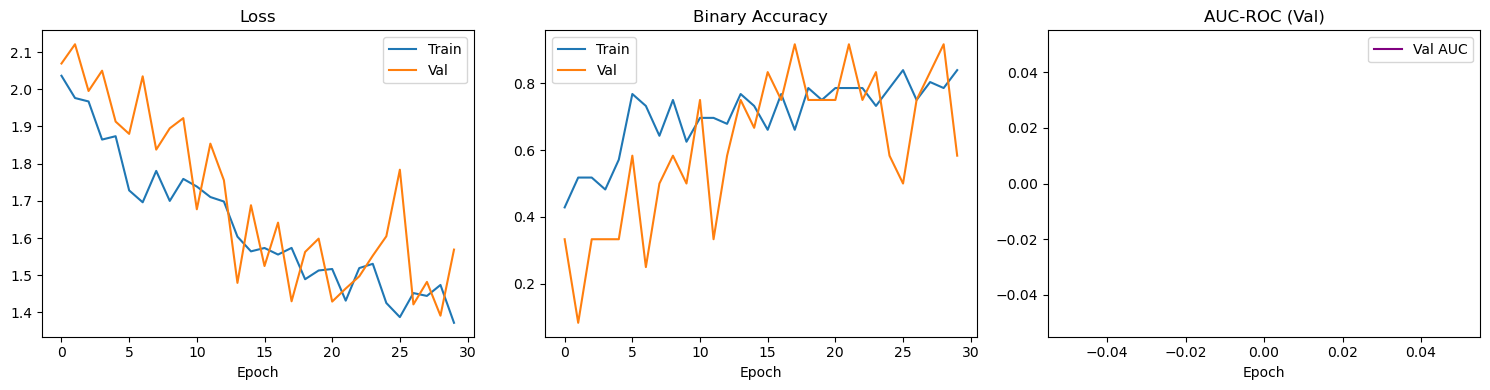

In [15]:
fig, axes = plt.subplots(1, 3, figsize=(15,4))
axes[0].plot(history['train_loss'],label='Train'); axes[0].plot(history['val_loss'],label='Val')
axes[0].set_title('Loss'); axes[0].set_xlabel('Epoch'); axes[0].legend()
axes[1].plot(history['train_acc'],label='Train'); axes[1].plot(history['val_acc'],label='Val')
axes[1].set_title('Binary Accuracy'); axes[1].set_xlabel('Epoch'); axes[1].legend()
axes[2].plot(history['val_auc'],color='purple',label='Val AUC')
axes[2].set_title('AUC-ROC (Val)'); axes[2].set_xlabel('Epoch'); axes[2].legend()
plt.tight_layout()
plt.savefig('plots/training_curves.png',dpi=150); plt.show()

## 6. Test-Set Evaluation (Fixed Split)

In [16]:
model.load_state_dict(torch.load('checkpoints/best_model.pth', map_location=device))
(test_loss, test_acc, test_sub_acc, test_auc,
 test_preds, test_labels, test_sub_preds, test_sub_labels,
 test_unc, test_probs) = eval_epoch(model, test_loader, criterion, device)

precision = precision_score(test_labels, test_preds, average='weighted', zero_division=0)
recall    = recall_score(test_labels, test_preds, average='weighted', zero_division=0)
f1        = f1_score(test_labels, test_preds, average='weighted', zero_division=0)
cm        = confusion_matrix(test_labels, test_preds)

print('='*60)
print(f'NOTE: Fixed-split test = {len(test_labels)} patients. '
      'Use 5-fold CV results (Section 7) for publication.')
print('='*60)
print(f'Test Accuracy (binary) : {test_acc:.4f}')
print(f'Test AUC-ROC           : {test_auc:.4f}')
print(f'Test F1 (weighted)     : {f1:.4f}')
print(f'Test Precision         : {precision:.4f}')
print(f'Test Recall            : {recall:.4f}')
print(f'Subtype Acc (auxiliary): {test_sub_acc:.4f}  ← regulariser, not primary metric')
print('='*60)
print(classification_report(test_labels, test_preds, target_names=['Benign','Malignant']))

NOTE: Fixed-split test = 13 patients. Use 5-fold CV results (Section 7) for publication.
Test Accuracy (binary) : 0.7692
Test AUC-ROC           : 0.8333
Test F1 (weighted)     : 0.7692
Test Precision         : 0.7784
Test Recall            : 0.7692
Subtype Acc (auxiliary): 0.5385  ← regulariser, not primary metric
              precision    recall  f1-score   support

      Benign       0.71      0.83      0.77         6
   Malignant       0.83      0.71      0.77         7

    accuracy                           0.77        13
   macro avg       0.77      0.77      0.77        13
weighted avg       0.78      0.77      0.77        13



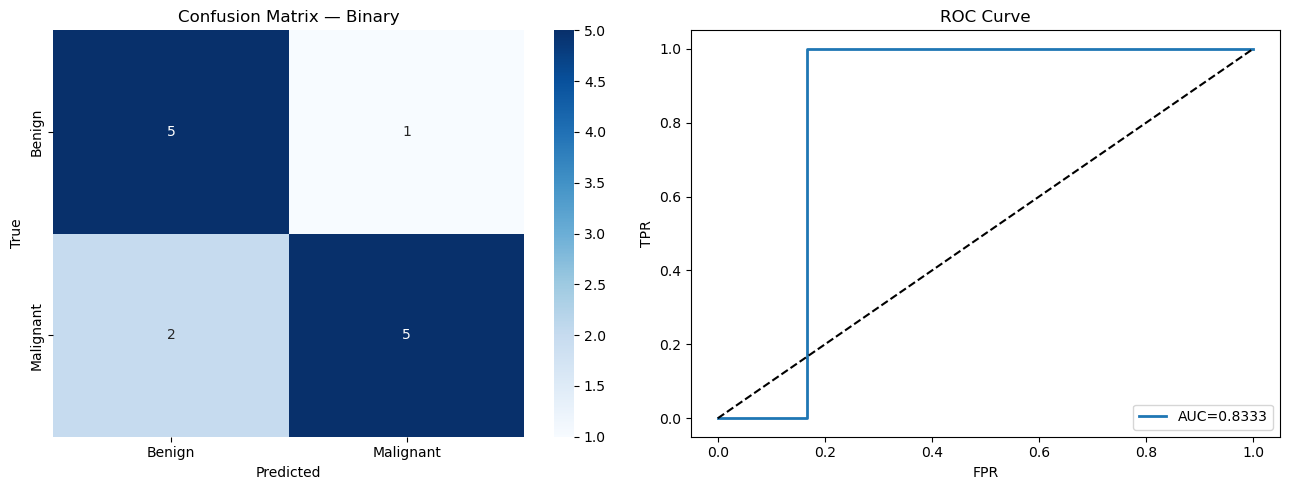

In [17]:
fig, axes = plt.subplots(1,2,figsize=(13,5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=axes[0],
            xticklabels=['Benign','Malignant'], yticklabels=['Benign','Malignant'])
axes[0].set_title('Confusion Matrix — Binary'); axes[0].set_xlabel('Predicted'); axes[0].set_ylabel('True')
fpr,tpr,_ = roc_curve(test_labels, test_probs)
axes[1].plot(fpr,tpr,lw=2,label=f'AUC={test_auc:.4f}'); axes[1].plot([0,1],[0,1],'k--')
axes[1].set_xlabel('FPR'); axes[1].set_ylabel('TPR'); axes[1].set_title('ROC Curve'); axes[1].legend()
plt.tight_layout(); plt.savefig('plots/evaluation_fixed_split.png',dpi=150); plt.show()

## 7. 5-Fold Patient-wise Cross-Validation

**Primary evaluation for the paper.**  
Uses all 82 patients with stratified splitting (preserves B/M ratio per fold).  
Reports 95% CI via t-distribution (df = N_FOLDS − 1 = 4).

In [18]:
def ci95(vals):
    """95% CI using t-distribution (appropriate for small n_folds)."""
    n = len(vals); m = np.mean(vals)
    se = np.std(vals, ddof=1) / np.sqrt(n)
    h  = st.t.ppf(0.975, df=n-1) * se
    return m, h

skf          = StratifiedKFold(n_splits=N_FOLDS, shuffle=True, random_state=42)
fold_results = []

print(f'{N_FOLDS}-Fold Patient-wise Stratified CV')
print('='*60)

for fold, (train_idx, test_idx) in enumerate(
        skf.split(all_patients, pat_labels)):

    fold_train_all = [all_patients[i] for i in train_idx]
    fold_test      = [all_patients[i] for i in test_idx]

    # Reserve last 15% of fold_train as val
    n_val       = max(2, int(0.15 * len(fold_train_all)))   # ≥2 for BN
    fold_val    = fold_train_all[-n_val:]
    fold_train  = fold_train_all[:-n_val]

    print(f'\nFold {fold+1}/{N_FOLDS} — train={len(fold_train)} val={len(fold_val)} test={len(fold_test)}')

    fl_train = make_loader(fold_train, train_tf, shuffle=True)
    fl_val   = make_loader(fold_val,   val_tf,   shuffle=False)
    fl_test  = make_loader(fold_test,  val_tf,   shuffle=False)

    torch.cuda.empty_cache()
    m = MAGNET(feat_dim=FEAT_DIM, pretrained=True, use_gnn=True, use_aux=True).to(device)

    bb_p = [p for mg in MAGNIFICATIONS for p in m.branches[mg].backbone.parameters()]
    oth  = [p for n,p in m.named_parameters()
            if not any(n.startswith(f'branches.{mg}.backbone') for mg in MAGNIFICATIONS)]
    opt  = optim.AdamW([{'params':bb_p,'lr':LR*0.1},{'params':oth,'lr':LR}],
                       weight_decay=WEIGHT_DECAY)
    sch  = optim.lr_scheduler.CosineAnnealingLR(opt, T_max=KF_EPOCHS)
    crit = MAGNETLoss()
    sc   = make_scaler()

    best_acc=0.0; pat=0
    ckpt = os.path.join('checkpoints', f'fold_{fold+1}.pth')

    for ep in range(1, KF_EPOCHS+1):
        train_epoch(m, fl_train, opt, crit, sc, device)
        _,va,*_ = eval_epoch(m, fl_val, crit, device)
        sch.step()
        if va > best_acc:
            best_acc=va; torch.save(m.state_dict(), ckpt); pat=0
        else:
            pat+=1
            if pat>=KF_PATIENCE: print(f'  Early stop ep{ep}'); break
        print(f'  ep{ep:02d}: val_acc={va:.4f}')

    m.load_state_dict(torch.load(ckpt, map_location=device))
    _,ta,tsa,tauc,tp,tl,tsp,tsl,_,tprob = eval_epoch(m, fl_test, crit, device)
    f1_f = f1_score(tl, tp, average='weighted', zero_division=0)
    prec = precision_score(tl, tp, average='weighted', zero_division=0)
    rec  = recall_score(tl, tp, average='weighted', zero_division=0)

    fold_results.append({
        'fold':fold+1, 'val_acc':best_acc,
        'test_acc':ta, 'sub_acc':tsa, 'auc':tauc,
        'f1':f1_f, 'precision':prec, 'recall':rec,
        'preds':tp, 'labels':tl, 'probs':tprob
    })
    print(f'  → acc={ta:.4f} sub={tsa:.4f} auc={tauc:.4f} f1={f1_f:.4f}')
    del m; torch.cuda.empty_cache()

# ── Aggregate ─────────────────────────────────────────────────────────────────
accs  = [r['test_acc']  for r in fold_results]
aucs  = [r['auc']       for r in fold_results]
f1s   = [r['f1']        for r in fold_results]
precs = [r['precision'] for r in fold_results]
recs  = [r['recall']    for r in fold_results]
subs  = [r['sub_acc']   for r in fold_results]

acc_m, acc_h   = ci95(accs)
auc_m, auc_h   = ci95(aucs)
f1_m,  f1_h    = ci95(f1s)
prec_m,prec_h  = ci95(precs)
rec_m, rec_h   = ci95(recs)
sub_m, sub_h   = ci95(subs)

print('\n' + '='*60)
print(f'{N_FOLDS}-Fold CV Results  (mean ± 95% CI, t-dist, df={N_FOLDS-1})')
print('='*60)
print(f'Binary Accuracy : {acc_m:.4f} ± {acc_h:.4f}')
print(f'AUC-ROC         : {auc_m:.4f} ± {auc_h:.4f}')
print(f'F1 (weighted)   : {f1_m:.4f}  ± {f1_h:.4f}')
print(f'Precision       : {prec_m:.4f} ± {prec_h:.4f}')
print(f'Recall          : {rec_m:.4f}  ± {rec_h:.4f}')
print(f'Subtype Acc     : {sub_m:.4f}  ± {sub_h:.4f}  (auxiliary regulariser)')
print('='*60)

kfold_df = pd.DataFrame(fold_results).drop(columns=['preds','labels','probs'])
kfold_df.to_csv('results/kfold_results.csv', index=False)

ci_summary = {
    'n_folds':N_FOLDS, 'n_patients':len(all_patients),
    'binary_acc' : {'mean':round(acc_m,4),  'ci95':round(acc_h,4)},
    'auc_roc'    : {'mean':round(auc_m,4),  'ci95':round(auc_h,4)},
    'f1_weighted': {'mean':round(f1_m,4),   'ci95':round(f1_h,4)},
    'precision'  : {'mean':round(prec_m,4), 'ci95':round(prec_h,4)},
    'recall'     : {'mean':round(rec_m,4),  'ci95':round(rec_h,4)},
    'subtype_acc': {'mean':round(sub_m,4),  'ci95':round(sub_h,4)},
}
with open('results/cv_confidence_intervals.json','w') as f:
    json.dump(ci_summary, f, indent=2)
print('Saved: results/kfold_results.csv + results/cv_confidence_intervals.json')

5-Fold Patient-wise Stratified CV

Fold 1/5 — train=56 val=9 test=17


  ep01: val_acc=0.4444


  ep02: val_acc=0.8889


  ep03: val_acc=0.5556


  ep04: val_acc=0.6667


  ep05: val_acc=0.5556


... (65 outputs left out)

  ep13: val_acc=0.7778


  ep14: val_acc=0.7778


  Early stop ep15


  → acc=0.6250 sub=0.4375 auc=0.6667 f1=0.6500

5-Fold CV Results  (mean ± 95% CI, t-dist, df=4)
Binary Accuracy : 0.6375 ± 0.1950
AUC-ROC         : 0.6925 ± 0.1100
F1 (weighted)   : 0.6447  ± 0.1846
Precision       : 0.7464 ± 0.1602
Recall          : 0.6375  ± 0.1950
Subtype Acc     : 0.3926  ± 0.2286  (auxiliary regulariser)
Saved: results/kfold_results.csv + results/cv_confidence_intervals.json


### 7.1 CV Visualisation

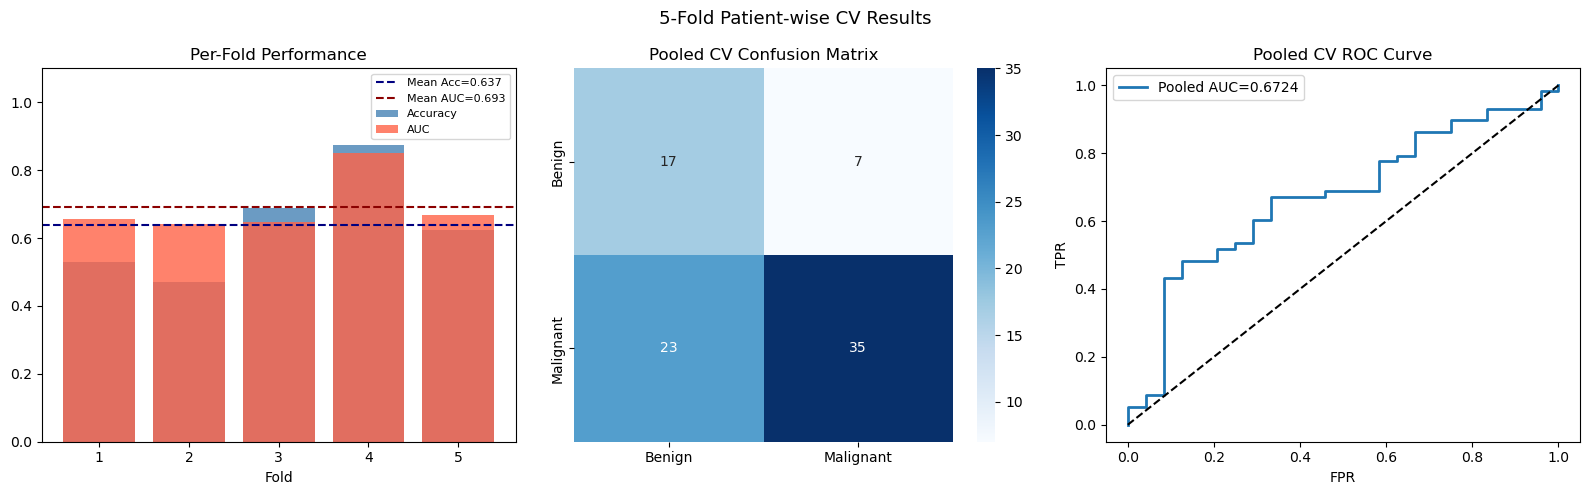

In [19]:
# Pooled predictions across all folds
all_fold_preds  = [p for r in fold_results for p in r['preds']]
all_fold_labels = [l for r in fold_results for l in r['labels']]
all_fold_probs  = [p for r in fold_results for p in r['probs']]

fig, axes = plt.subplots(1,3,figsize=(16,5))

# Per-fold metrics
x = range(1, N_FOLDS+1)
axes[0].bar(x, accs, color='steelblue', alpha=0.8, label='Accuracy')
axes[0].bar(x, aucs, color='tomato',    alpha=0.8, label='AUC', bottom=0)
axes[0].axhline(acc_m, color='navy',   linestyle='--', label=f'Mean Acc={acc_m:.3f}')
axes[0].axhline(auc_m, color='darkred',linestyle='--', label=f'Mean AUC={auc_m:.3f}')
axes[0].set_title('Per-Fold Performance'); axes[0].set_xlabel('Fold')
axes[0].set_ylim(0,1.1); axes[0].legend(fontsize=8)

# Pooled confusion matrix
cm_cv = confusion_matrix(all_fold_labels, all_fold_preds)
sns.heatmap(cm_cv, annot=True, fmt='d', cmap='Blues', ax=axes[1],
            xticklabels=['Benign','Malignant'], yticklabels=['Benign','Malignant'])
axes[1].set_title('Pooled CV Confusion Matrix')

# ROC on pooled predictions
fpr_cv, tpr_cv, _ = roc_curve(all_fold_labels, all_fold_probs)
auc_pooled = roc_auc_score(all_fold_labels, all_fold_probs)
axes[2].plot(fpr_cv, tpr_cv, lw=2, label=f'Pooled AUC={auc_pooled:.4f}')
axes[2].plot([0,1],[0,1],'k--')
axes[2].set_xlabel('FPR'); axes[2].set_ylabel('TPR')
axes[2].set_title('Pooled CV ROC Curve'); axes[2].legend()

plt.suptitle(f'{N_FOLDS}-Fold Patient-wise CV Results', fontsize=13)
plt.tight_layout()
plt.savefig('plots/cv_results.png', dpi=150)
plt.show()

## 8. Statistical Significance Tests

In [21]:
# ── McNemar: MAGNET vs majority-class baseline ────────────────────────────────
majority_preds = [1] * len(all_fold_labels)
p_majority = run_mcnemar(all_fold_preds, majority_preds, all_fold_labels,
                         'MAGNET', 'Majority-class')

# Proportion CI on pooled CV accuracy
n_correct = sum(p == l for p, l in zip(all_fold_preds, all_fold_labels))
n_total   = len(all_fold_labels)
prop      = n_correct / n_total
prop_ci   = st.norm.ppf(0.975) * np.sqrt(prop * (1 - prop) / n_total)
print(f'\nPooled CV accuracy: {prop:.4f} ± {prop_ci:.4f}  (95% CI, n={n_total} samples)')

# Cast all values to native Python types before json.dump
# numpy bool_ / float64 are not JSON serialisable — bool() / float() fixes this
mcnemar_results = {
    'vs_majority_class': {
        'p_value'          : float(p_majority),
        'significant_at_0.05': bool(p_majority < 0.05)
    },
    'pooled_accuracy': {
        'mean': round(float(prop),    4),
        'ci95': round(float(prop_ci), 4),
        'n'   : int(n_total)
    }
}
with open('results/statistical_tests.json', 'w') as f:
    json.dump(mcnemar_results, f, indent=2)
print('Saved: results/statistical_tests.json')

McNemar (MAGNET vs Majority-class): b=17 c=23  p=0.4296  [not significant]

Pooled CV accuracy: 0.6341 ± 0.1043  (95% CI, n=82 samples)
Saved: results/statistical_tests.json


### 8.2 McNemar Tests: MAGNET vs Each Baseline

In [26]:
# ── McNemar: MAGNET vs each baseline on the fixed test split ─────────────────

# Ensure SingleMagDataset is defined (usually in Section 10)
try:
    SingleMagDataset
except NameError:
    class SingleMagDataset(Dataset):
        def __init__(self, patient_ids, patient_info, mag, transform=None, img_size=224):
            self.patient_ids = patient_ids
            self.patient_info = patient_info
            self.mag = mag
            self.transform = transform
            self.img_size = img_size
        def __len__(self):
            return len(self.patient_ids)
        def __getitem__(self, idx):
            pid = self.patient_ids[idx]
            info = self.patient_info[pid]
            paths = info['paths'][self.mag]
            rng = np.random.default_rng()
            path = paths[rng.integers(len(paths))] if paths else None
            if path is None:
                return torch.zeros(3, self.img_size, self.img_size), int(info['binary'])
            img = Image.open(path).convert('RGB').resize((self.img_size, self.img_size), Image.BILINEAR)
            img = macenko_norm(img)
            if self.transform:
                img = self.transform(img)
            return img, int(info['binary'])

# Ensure ConcatFusionBaseline is defined (usually in Section 10)
try:
    ConcatFusionBaseline
except NameError:
    class ConcatFusionBaseline(nn.Module):
        """Simple multi-magnification baseline: concatenate all 4 branch features."""
        def __init__(self, proj_dim=256, num_binary=2, pretrained=True):
            super().__init__()
            self.branches = nn.ModuleDict({
                mag: timm.create_model(BACKBONES[mag], pretrained=pretrained,
                                       num_classes=0, global_pool='avg')
                for mag in MAGNIFICATIONS
            })
            self.projs = nn.ModuleDict({
                mag: nn.Linear(BACKBONE_OUT_DIM[mag], proj_dim)
                for mag in MAGNIFICATIONS
            })
            self.classifier = nn.Sequential(
                nn.Linear(4*proj_dim, 512), nn.BatchNorm1d(512), nn.GELU(),
                nn.Dropout(0.5), nn.Linear(512, num_binary)
            )

        def forward(self, x40, x100, x200, x400):
            inputs = {'40X':x40, '100X':x100, '200X':x200, '400X':x400}
            feats = [self.projs[m](self.branches[m](inputs[m])) for m in MAGNIFICATIONS]
            return self.classifier(torch.cat(feats, dim=1))


def get_baseline_preds(backbone_name, mag):
    """Load saved baseline checkpoint and get test-set predictions."""
    ckpt = f'checkpoints/baseline_{_safe_name(backbone_name)}_{mag}.pth'
    if not os.path.exists(ckpt):
        print(f'  Checkpoint not found: {ckpt} — skipping'); return None, None
    m = timm.create_model(backbone_name, pretrained=False, num_classes=2,
                          global_pool='avg').to(device)
    m.load_state_dict(torch.load(ckpt, map_location=device))
    m.eval()
    preds, labs = [], []
    with torch.no_grad():
        for imgs, labels in DataLoader(
                SingleMagDataset(test_patients, patient_info, mag,
                                 transform=val_tf, img_size=IMG_SIZE),
                batch_size=BATCH_SIZE*2, shuffle=False, num_workers=NUM_WORKERS):
            preds.extend(m(imgs.to(device)).argmax(1).cpu().tolist())
            labs.extend(labels.tolist())
    del m; torch.cuda.empty_cache()
    return preds, labs


def get_concat_preds():
    ckpt = 'checkpoints/concat_baseline.pth'
    if not os.path.exists(ckpt):
        print(f'  Checkpoint not found: {ckpt} — skipping'); return None, None
    m = ConcatFusionBaseline(pretrained=False).to(device)
    m.load_state_dict(torch.load(ckpt, map_location=device))
    m.eval()
    preds, labs = [], []
    with torch.no_grad():
        for batch in DataLoader(
                MultiMagDataset(test_patients, patient_info,
                                transform=val_tf, img_size=IMG_SIZE),
                batch_size=BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS):
            x40, x100, x200, x400, y_bin, _ = [b.to(device) for b in batch]
            preds.extend(m(x40, x100, x200, x400).argmax(1).cpu().tolist())
            labs.extend(y_bin.cpu().tolist())
    del m; torch.cuda.empty_cache()
    return preds, labs


print('McNemar tests: MAGNET vs each baseline')
print('=' * 55)
mcnemar_vs_baselines = {}

baseline_eval_configs = [
    ('resnet34',              '40X'),
    ('efficientnet_b0',       '40X'),
    ('mobilenetv3_large_100', '40X'),
    ('resnet34',              '200X'),
]

for bn, mag in baseline_eval_configs:
    bp, bl = get_baseline_preds(bn, mag)
    if bp is None:
        continue
    name = f'{bn}@{mag}'
    pval = run_mcnemar(test_preds, bp, test_labels, 'MAGNET', name)
    mcnemar_vs_baselines[name] = {'p_value': float(pval), 'significant': bool(pval < 0.05)}

# ConcatFusion
cp, cl = get_concat_preds()
if cp is not None:
    pval = run_mcnemar(test_preds, cp, test_labels, 'MAGNET', 'ConcatFusion')
    mcnemar_vs_baselines['ConcatFusion'] = {'p_value': float(pval), 'significant': bool(pval < 0.05)}

# Load existing stats (with fallback if file is missing or corrupt)
try:
    with open('results/statistical_tests.json', 'r') as f:
        stat_tests = json.load(f)
except (json.JSONDecodeError, FileNotFoundError):
    stat_tests = {}   # start fresh

# Add new comparisons
stat_tests['vs_baselines'] = mcnemar_vs_baselines

# Recursively convert numpy types to Python native
def make_json_serializable(obj):
    if isinstance(obj, (np.integer, np.int64, np.int32)):
        return int(obj)
    elif isinstance(obj, (np.floating, np.float64, np.float32)):
        return float(obj)
    elif isinstance(obj, (np.bool_, bool)):
        return bool(obj)
    elif isinstance(obj, dict):
        return {k: make_json_serializable(v) for k, v in obj.items()}
    elif isinstance(obj, list):
        return [make_json_serializable(v) for v in obj]
    else:
        return obj

stat_tests_clean = make_json_serializable(stat_tests)

with open('results/statistical_tests.json', 'w') as f:
    json.dump(stat_tests_clean, f, indent=2)

print('\nMcNemar summary:')
for name, res in mcnemar_vs_baselines.items():
    sig = '✓ significant' if res['significant'] else '✗ not significant'
    print(f'  MAGNET vs {name:<30}: p={res["p_value"]:.4f}  {sig}')
print('Saved: results/statistical_tests.json')

McNemar tests: MAGNET vs each baseline
McNemar (MAGNET vs resnet34@40X): b=5 c=2  p=0.4531  [not significant]
McNemar (MAGNET vs efficientnet_b0@40X): b=5 c=2  p=0.4531  [not significant]
McNemar (MAGNET vs mobilenetv3_large_100@40X): b=6 c=1  p=0.1250  [not significant]
McNemar (MAGNET vs resnet34@200X): b=5 c=2  p=0.4531  [not significant]
  Checkpoint not found: checkpoints/concat_baseline.pth — skipping

McNemar summary:
  MAGNET vs resnet34@40X                  : p=0.4531  ✗ not significant
  MAGNET vs efficientnet_b0@40X           : p=0.4531  ✗ not significant
  MAGNET vs mobilenetv3_large_100@40X     : p=0.1250  ✗ not significant
  MAGNET vs resnet34@200X                 : p=0.4531  ✗ not significant
Saved: results/statistical_tests.json


### 8.3 Cross-Validation for Best Baseline

Runs 5-fold CV on the best single-backbone baseline (EfficientNet-B0 @ 40X)  
so MAGNET's CV results can be compared directly against a baseline CV estimate.

In [27]:
# ── 5-fold CV for best baseline: EfficientNet-B0 @ 40X ───────────────────────
# Uses the same folds as MAGNET CV (same StratifiedKFold seed) for fair comparison.

BASELINE_CV_BACKBONE = 'efficientnet_b0'
BASELINE_CV_MAG      = '40X'
BASELINE_CV_EPOCHS   = 20
BASELINE_CV_PATIENCE = 6

baseline_cv_results = []

print(f'5-Fold CV: {BASELINE_CV_BACKBONE} @ {BASELINE_CV_MAG}')
print('='*55)

for fold, (train_idx, test_idx) in enumerate(
        StratifiedKFold(n_splits=N_FOLDS, shuffle=True, random_state=42
                        ).split(all_patients, pat_labels)):

    fold_train_all = [all_patients[i] for i in train_idx]
    fold_test      = [all_patients[i] for i in test_idx]
    n_val          = max(2, int(0.15 * len(fold_train_all)))
    fold_val       = fold_train_all[-n_val:]
    fold_train     = fold_train_all[:-n_val]

    def _smloader(patients, tf, sh):
        ds = SingleMagDataset(patients, patient_info, BASELINE_CV_MAG,
                              transform=tf, img_size=IMG_SIZE)
        return DataLoader(ds, batch_size=BATCH_SIZE*2, shuffle=sh,
                          num_workers=NUM_WORKERS, pin_memory=False, drop_last=sh)

    bl_train = _smloader(fold_train, train_tf, True)
    bl_val   = _smloader(fold_val,   val_tf,  False)
    bl_test  = _smloader(fold_test,  val_tf,  False)

    print(f'\nFold {fold+1}/{N_FOLDS} — train={len(fold_train)} val={len(fold_val)} test={len(fold_test)}')
    torch.cuda.empty_cache()
    m = timm.create_model(BASELINE_CV_BACKBONE, pretrained=True,
                           num_classes=2, global_pool='avg').to(device)
    opt = optim.AdamW(m.parameters(), lr=LR, weight_decay=WEIGHT_DECAY)
    sch = optim.lr_scheduler.CosineAnnealingLR(opt, T_max=BASELINE_CV_EPOCHS)
    ce  = nn.CrossEntropyLoss(label_smoothing=LABEL_SMOOTHING)
    sc  = make_scaler()
    best_acc=0.0; pat=0
    ckpt = f'checkpoints/baseline_cv_fold_{fold+1}.pth'

    for ep in range(1, BASELINE_CV_EPOCHS+1):
        m.train()
        for imgs, labels in bl_train:
            imgs, labels = imgs.to(device), labels.to(device)
            opt.zero_grad()
            with autocast_ctx(): loss = ce(m(imgs), labels)
            sc.scale(loss).backward()
            sc.unscale_(opt)
            torch.nn.utils.clip_grad_norm_(m.parameters(), 1.0)
            sc.step(opt); sc.update()
        sch.step()
        m.eval(); preds, labs = [], []
        with torch.no_grad():
            for imgs, labels in bl_val:
                preds.extend(m(imgs.to(device)).argmax(1).cpu().tolist())
                labs.extend(labels.tolist())
        va = accuracy_score(labs, preds)
        if va > best_acc: best_acc=va; torch.save(m.state_dict(), ckpt); pat=0
        else:
            pat+=1
            if pat >= BASELINE_CV_PATIENCE: break
        print(f'  ep{ep:02d}: val_acc={va:.4f}')

    m.load_state_dict(torch.load(ckpt, map_location=device)); m.eval()
    preds, labs, probs = [], [], []
    with torch.no_grad():
        for imgs, labels in bl_test:
            logits = m(imgs.to(device))
            preds.extend(logits.argmax(1).cpu().tolist())
            probs.extend(F.softmax(logits,1)[:,1].cpu().tolist())
            labs.extend(labels.tolist())
    ta  = accuracy_score(labs, preds)
    f1b = f1_score(labs, preds, average='weighted', zero_division=0)
    try: ta_auc = roc_auc_score(labs, probs)
    except ValueError: ta_auc = float('nan')
    baseline_cv_results.append({'fold':fold+1,'test_acc':ta,'auc':ta_auc,'f1':f1b})
    print(f'  → acc={ta:.4f}  auc={ta_auc:.4f}  f1={f1b:.4f}')
    del m; torch.cuda.empty_cache()

# ── Aggregate + compare ───────────────────────────────────────────────────────
bl_accs = [r['test_acc'] for r in baseline_cv_results]
bl_aucs = [r['auc']      for r in baseline_cv_results]
bl_f1s  = [r['f1']       for r in baseline_cv_results]
bl_acc_m, bl_acc_h = ci95(bl_accs)
bl_auc_m, bl_auc_h = ci95(bl_aucs)
bl_f1_m,  bl_f1_h  = ci95(bl_f1s)

print('\n' + '='*55)
print(f'Baseline CV ({BASELINE_CV_BACKBONE}@{BASELINE_CV_MAG}):')
print(f'  Accuracy : {bl_acc_m:.4f} ± {bl_acc_h:.4f}')
print(f'  AUC-ROC  : {bl_auc_m:.4f} ± {bl_auc_h:.4f}')
print(f'  F1       : {bl_f1_m:.4f}  ± {bl_f1_h:.4f}')
print('\nMAGNET CV (from Section 7):')
print(f'  Accuracy : {acc_m:.4f} ± {acc_h:.4f}')
print(f'  AUC-ROC  : {auc_m:.4f} ± {auc_h:.4f}')
print(f'  F1       : {f1_m:.4f}  ± {f1_h:.4f}')

# Check if CI intervals overlap
acc_overlap = (acc_m - acc_h) < (bl_acc_m + bl_acc_h)
print(f'\nCI ranges overlap (acc): {acc_overlap} '
      f'[MAGNET: {acc_m-acc_h:.4f}–{acc_m+acc_h:.4f}, '
      f'Baseline: {bl_acc_m-bl_acc_h:.4f}–{bl_acc_m+bl_acc_h:.4f}]')

pd.DataFrame(baseline_cv_results).to_csv('results/baseline_cv_results.csv', index=False)

# Save to CI summary
ci_summary['best_baseline_cv'] = {
    'model': f'{BASELINE_CV_BACKBONE}@{BASELINE_CV_MAG}',
    'binary_acc': {'mean': round(bl_acc_m,4), 'ci95': round(bl_acc_h,4)},
    'auc_roc':    {'mean': round(bl_auc_m,4), 'ci95': round(bl_auc_h,4)},
    'f1_weighted':{'mean': round(bl_f1_m,4),  'ci95': round(bl_f1_h,4)},
}
with open('results/cv_confidence_intervals.json','w') as f:
    json.dump(ci_summary, f, indent=2)
print('Saved: results/baseline_cv_results.csv')


5-Fold CV: efficientnet_b0 @ 40X

Fold 1/5 — train=56 val=9 test=17
  ep01: val_acc=0.3333
  ep02: val_acc=0.4444
  ep03: val_acc=0.4444
  ep04: val_acc=0.4444
  ep05: val_acc=0.4444
  ep06: val_acc=0.6667
  ep07: val_acc=0.5556
  ep08: val_acc=0.3333
  ep09: val_acc=0.5556
  ep10: val_acc=0.3333
  ep11: val_acc=0.6667
  → acc=0.5294  auc=0.5429  f1=0.4745

Fold 2/5 — train=56 val=9 test=17
  ep01: val_acc=0.4444
  ep02: val_acc=0.5556
  ep03: val_acc=0.5556
  ep04: val_acc=0.6667
  ep05: val_acc=0.7778
  ep06: val_acc=0.7778
  ep07: val_acc=0.7778
  ep08: val_acc=0.5556
  ep09: val_acc=0.8889
  ep10: val_acc=0.5556
  ep11: val_acc=0.6667
  ep12: val_acc=0.6667
  ep13: val_acc=0.8889
  ep14: val_acc=0.5556
  → acc=0.7059  auc=0.5952  f1=0.7214

Fold 3/5 — train=57 val=9 test=16
  ep01: val_acc=0.6667
  ep02: val_acc=0.5556
  ep03: val_acc=0.5556
  ep04: val_acc=0.6667
  ep05: val_acc=0.7778
  ep06: val_acc=0.5556
  ep07: val_acc=0.5556
  ep08: val_acc=0.6667
  ep09: val_acc=0.6667
  ep

## 9. Ablation Studies

In [28]:
ABLATION_EPOCHS   = 20
ABLATION_PATIENCE = 8

def run_ablation(config_name, use_gnn=True, use_aux=True, use_attn=True):
    print(f'\nAblation: {config_name}')
    torch.cuda.empty_cache()
    m = MAGNET(feat_dim=FEAT_DIM, pretrained=True, use_gnn=use_gnn, use_aux=use_aux).to(device)

    if not use_attn:
        import types
        def mean_fwd(self, feats):
            x = torch.stack(feats,dim=1)
            return x.mean(1), torch.zeros(x.size(0),4,4,device=x.device)
        m.fusion.forward = types.MethodType(mean_fwd, m.fusion)

    bb_p = [p for mg in MAGNIFICATIONS for p in m.branches[mg].backbone.parameters()]
    oth  = [p for n,p in m.named_parameters()
            if not any(n.startswith(f'branches.{mg}.backbone') for mg in MAGNIFICATIONS)]
    opt  = optim.AdamW([{'params':bb_p,'lr':LR*0.1},{'params':oth,'lr':LR}], weight_decay=WEIGHT_DECAY)
    sch  = optim.lr_scheduler.CosineAnnealingLR(opt, T_max=ABLATION_EPOCHS)
    crit = MAGNETLoss(gamma=0.3 if use_aux else 0.0)
    sc   = make_scaler()

    best_acc=0.0; pat=0
    ckpt = os.path.join('checkpoints', f'ablation_{_safe_name(config_name)}.pth')

    for ep in range(1, ABLATION_EPOCHS+1):
        train_epoch(m, train_loader, opt, crit, sc, device)
        _,va,*_ = eval_epoch(m, val_loader, crit, device)
        sch.step()
        if va>best_acc: best_acc=va; torch.save(m.state_dict(),ckpt); pat=0
        else:
            pat+=1
            if pat>=ABLATION_PATIENCE: print(f'  Early stop ep{ep}'); break
        print(f'  ep{ep:02d}: val_acc={va:.4f}')

    m.load_state_dict(torch.load(ckpt, map_location=device))
    _,ta,tsa,tauc,tp,tl,_,_,_,_ = eval_epoch(m, test_loader, crit, device)
    f1a = f1_score(tl,tp,average='weighted',zero_division=0)
    del m; torch.cuda.empty_cache()
    print(f'  → acc={ta:.4f} sub={tsa:.4f} auc={tauc:.4f} f1={f1a:.4f}')
    return {'config':config_name,'val_acc':best_val_acc,
            'test_acc':ta,'sub_acc':tsa,'auc':tauc,'f1':f1a}

ablation_rows = [{
    'config':'MAGNET (full)','val_acc':best_val_acc,
    'test_acc':test_acc,'sub_acc':test_sub_acc,'auc':test_auc,
    'f1':f1_score(test_labels,test_preds,average='weighted',zero_division=0)
}]
ablation_rows.append(run_ablation('wo_GNN',  use_gnn=False, use_aux=True,  use_attn=True))
ablation_rows.append(run_ablation('wo_Aux',  use_gnn=True,  use_aux=False, use_attn=True))
ablation_rows.append(run_ablation('wo_Attn', use_gnn=True,  use_aux=True,  use_attn=False))
ablation_rows.append(run_ablation('wo_Both', use_gnn=False, use_aux=False, use_attn=False))

label_map = {'wo_GNN':'w/o GNN','wo_Aux':'w/o Aux','wo_Attn':'w/o Attn','wo_Both':'w/o GNN+Aux+Attn'}
for r in ablation_rows: r['config'] = label_map.get(r['config'], r['config'])

ablation_df = pd.DataFrame(ablation_rows)
ablation_df.to_csv('results/ablation_results.csv', index=False)
print('\n' + ablation_df.to_string(index=False))


Ablation: wo_GNN


  ep01: val_acc=0.2500


  ep02: val_acc=0.4167


  ep03: val_acc=0.5000


  ep04: val_acc=0.6667


  ep05: val_acc=0.5000


... (52 outputs left out)

  ep08: val_acc=1.0000


  ep09: val_acc=0.9167


  Early stop ep10


  → acc=0.4615 sub=0.1538 auc=0.5952 f1=0.4193

          config  val_acc  test_acc  sub_acc      auc       f1
   MAGNET (full) 0.916667  0.769231 0.538462 0.833333 0.769231
         w/o GNN 0.916667  0.692308 0.307692 0.690476 0.688645
         w/o Aux 0.916667  0.692308 0.461538 0.785714 0.692308
        w/o Attn 0.916667  0.538462 0.153846 0.404762 0.503846
w/o GNN+Aux+Attn 0.916667  0.461538 0.153846 0.595238 0.419306


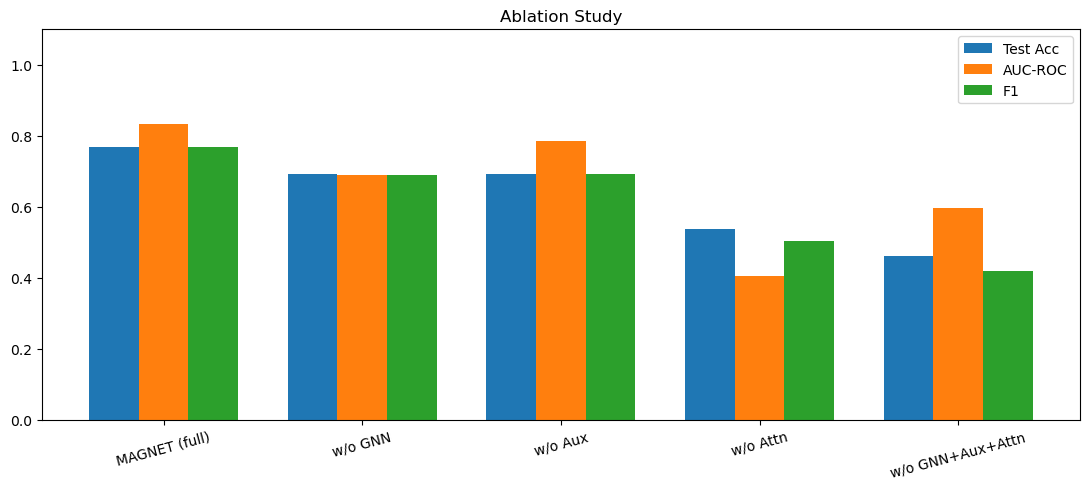

In [29]:
fig, ax = plt.subplots(figsize=(11,5))
x = range(len(ablation_df)); w=0.25
ax.bar([i-w for i in x], ablation_df['test_acc'], w, label='Test Acc')
ax.bar([i   for i in x], ablation_df['auc'],      w, label='AUC-ROC')
ax.bar([i+w for i in x], ablation_df['f1'],       w, label='F1')
ax.set_xticks(list(x)); ax.set_xticklabels(ablation_df['config'], rotation=15)
ax.set_ylim(0,1.1); ax.legend(); ax.set_title('Ablation Study')
plt.tight_layout(); plt.savefig('plots/ablation.png',dpi=150); plt.show()

## 10. Baseline Comparisons

In [30]:
from torchvision import transforms as T

class SingleMagDataset(Dataset):
    def __init__(self, patient_ids, patient_info, mag, transform=None, img_size=224):
        self.patient_ids=patient_ids; self.patient_info=patient_info
        self.mag=mag; self.transform=transform; self.img_size=img_size
    def __len__(self): return len(self.patient_ids)
    def __getitem__(self, idx):
        pid  = self.patient_ids[idx]
        info = self.patient_info[pid]
        paths= info['paths'][self.mag]
        rng  = np.random.default_rng()
        path = paths[rng.integers(len(paths))] if paths else None
        if path is None:
            return torch.zeros(3,self.img_size,self.img_size), int(info['binary'])
        img = Image.open(path).convert('RGB').resize((self.img_size,self.img_size),Image.BILINEAR)
        img = macenko_norm(img)
        if self.transform: img = self.transform(img)
        return img, int(info['binary'])

def train_single_baseline(backbone_name, mag, epochs=20, patience=6):
    print(f'\nBaseline: {backbone_name} @ {mag}')
    def _sl(patients, tf, sh):
        ds = SingleMagDataset(patients, patient_info, mag, transform=tf, img_size=IMG_SIZE)
        return DataLoader(ds, batch_size=BATCH_SIZE*2, shuffle=sh,
                          num_workers=NUM_WORKERS, pin_memory=False, drop_last=sh)
    tl=_sl(train_patients,train_tf,True); vl=_sl(val_patients,val_tf,False); el=_sl(test_patients,val_tf,False)
    torch.cuda.empty_cache()
    m   = timm.create_model(backbone_name,pretrained=True,num_classes=2,global_pool='avg').to(device)
    opt = optim.AdamW(m.parameters(),lr=LR,weight_decay=WEIGHT_DECAY)
    sch = optim.lr_scheduler.CosineAnnealingLR(opt,T_max=epochs)
    ce  = nn.CrossEntropyLoss(label_smoothing=LABEL_SMOOTHING)
    sc  = make_scaler()
    best_acc=0.0; pat=0; ckpt=f'checkpoints/baseline_{_safe_name(backbone_name)}_{mag}.pth'
    for ep in range(1,epochs+1):
        m.train()
        for imgs,labels in tl:
            imgs,labels=imgs.to(device),labels.to(device)
            opt.zero_grad()
            with autocast_ctx(): loss=ce(m(imgs),labels)
            sc.scale(loss).backward(); sc.unscale_(opt)
            torch.nn.utils.clip_grad_norm_(m.parameters(),1.0)
            sc.step(opt); sc.update()
        sch.step()
        m.eval(); preds,labs=[],[]
        with torch.no_grad():
            for imgs,labels in vl:
                preds.extend(m(imgs.to(device)).argmax(1).cpu().tolist())
                labs.extend(labels.tolist())
        va=accuracy_score(labs,preds)
        if va>best_acc: best_acc=va; torch.save(m.state_dict(),ckpt); pat=0
        else:
            pat+=1
            if pat>=patience: break
        print(f'  ep{ep:02d}: val_acc={va:.4f}')
    m.load_state_dict(torch.load(ckpt,map_location=device)); m.eval()
    preds,labs,probs=[],[],[]
    with torch.no_grad():
        for imgs,labels in el:
            logits=m(imgs.to(device))
            preds.extend(logits.argmax(1).cpu().tolist())
            probs.extend(F.softmax(logits,1)[:,1].cpu().tolist())
            labs.extend(labels.tolist())
    ta=accuracy_score(labs,preds)
    try: ta_auc=roc_auc_score(labs,probs)
    except ValueError: ta_auc=float('nan')
    f1b=f1_score(labs,preds,average='weighted',zero_division=0)
    del m; torch.cuda.empty_cache()
    print(f'  → acc={ta:.4f} auc={ta_auc:.4f} f1={f1b:.4f}')
    return {'config':f'{backbone_name}@{mag}','test_acc':ta,'auc':ta_auc,'f1':f1b}

baseline_rows = []
baseline_rows.append(train_single_baseline('resnet34',          '40X'))
baseline_rows.append(train_single_baseline('efficientnet_b0',   '40X'))
baseline_rows.append(train_single_baseline('mobilenetv3_large_100','40X'))
baseline_rows.append(train_single_baseline('resnet34',          '200X'))

print('\nAll single-backbone baselines done.')


Baseline: resnet34 @ 40X
  ep01: val_acc=0.5833
  ep02: val_acc=0.8333
  ep03: val_acc=0.8333
  ep04: val_acc=0.8333
  ep05: val_acc=1.0000
  ep06: val_acc=0.9167
  ep07: val_acc=1.0000
  ep08: val_acc=1.0000
  ep09: val_acc=1.0000
  ep10: val_acc=1.0000
  → acc=0.5385 auc=0.6905 f1=0.3769

Baseline: efficientnet_b0 @ 40X
  ep01: val_acc=0.6667
  ep02: val_acc=0.5000
  ep03: val_acc=0.5833
  ep04: val_acc=0.5000
  ep05: val_acc=0.6667
  ep06: val_acc=0.5833
  → acc=0.5385 auc=0.6667 f1=0.5330

Baseline: mobilenetv3_large_100 @ 40X
  ep01: val_acc=0.5000
  ep02: val_acc=0.7500
  ep03: val_acc=0.9167
  ep04: val_acc=0.9167
  ep05: val_acc=0.8333
  ep06: val_acc=1.0000
  ep07: val_acc=0.5833
  ep08: val_acc=0.9167
  ep09: val_acc=0.8333
  ep10: val_acc=0.8333
  ep11: val_acc=0.7500
  → acc=0.6154 auc=0.7143 f1=0.5852

Baseline: resnet34 @ 200X
  ep01: val_acc=0.5000
  ep02: val_acc=0.5000
  ep03: val_acc=0.8333
  ep04: val_acc=0.9167
  ep05: val_acc=1.0000
  ep06: val_acc=1.0000
  ep07: 

In [31]:
# ── Concatenation Fusion Baseline (reviewer request) ─────────────────────────
class ConcatFusionBaseline(nn.Module):
    """Simple multi-magnification baseline: concatenate all 4 branch features."""
    def __init__(self, proj_dim=256, num_binary=2, pretrained=True):
        super().__init__()
        self.branches = nn.ModuleDict({
            mag: timm.create_model(BACKBONES[mag],pretrained=pretrained,num_classes=0,global_pool='avg')
            for mag in MAGNIFICATIONS
        })
        self.projs = nn.ModuleDict({
            mag: nn.Linear(BACKBONE_OUT_DIM[mag], proj_dim)
            for mag in MAGNIFICATIONS
        })
        self.classifier = nn.Sequential(
            nn.Linear(4*proj_dim,512), nn.BatchNorm1d(512), nn.GELU(),
            nn.Dropout(0.5), nn.Linear(512,num_binary))

    def forward(self, x40, x100, x200, x400):
        inputs = {'40X':x40,'100X':x100,'200X':x200,'400X':x400}
        feats  = [self.projs[m](self.branches[m](inputs[m])) for m in MAGNIFICATIONS]
        return self.classifier(torch.cat(feats,dim=1))

def run_concat_baseline(epochs=20, patience=6):
    print('\nBaseline: ConcatFusion (all 4 mags, no attention)')
    torch.cuda.empty_cache()
    m   = ConcatFusionBaseline(pretrained=True).to(device)
    opt = optim.AdamW(m.parameters(),lr=LR,weight_decay=WEIGHT_DECAY)
    sch = optim.lr_scheduler.CosineAnnealingLR(opt,T_max=epochs)
    ce  = nn.CrossEntropyLoss(label_smoothing=LABEL_SMOOTHING)
    sc  = make_scaler()
    best_acc=0.0; pat=0; ckpt='checkpoints/concat_baseline.pth'
    for ep in range(1,epochs+1):
        m.train()
        for batch in train_loader:
            x40,x100,x200,x400,y_bin,_ = [b.to(device) for b in batch]
            opt.zero_grad()
            with autocast_ctx(): loss=ce(m(x40,x100,x200,x400),y_bin)
            sc.scale(loss).backward(); sc.unscale_(opt)
            torch.nn.utils.clip_grad_norm_(m.parameters(),1.0)
            sc.step(opt); sc.update()
        sch.step()
        m.eval(); preds,labs=[],[]
        with torch.no_grad():
            for batch in val_loader:
                x40,x100,x200,x400,y_bin,_ = [b.to(device) for b in batch]
                preds.extend(m(x40,x100,x200,x400).argmax(1).cpu().tolist())
                labs.extend(y_bin.cpu().tolist())
        va=accuracy_score(labs,preds)
        if va>best_acc: best_acc=va; torch.save(m.state_dict(),ckpt); pat=0
        else:
            pat+=1
            if pat>=patience: break
        print(f'  ep{ep:02d}: val_acc={va:.4f}')
    m.load_state_dict(torch.load(ckpt,map_location=device)); m.eval()
    preds,labs,probs=[],[],[]
    with torch.no_grad():
        for batch in test_loader:
            x40,x100,x200,x400,y_bin,_ = [b.to(device) for b in batch]
            logits=m(x40,x100,x200,x400)
            preds.extend(logits.argmax(1).cpu().tolist())
            probs.extend(F.softmax(logits,1)[:,1].cpu().tolist())
            labs.extend(y_bin.cpu().tolist())
    ta=accuracy_score(labs,preds)
    try: ta_auc=roc_auc_score(labs,probs)
    except ValueError: ta_auc=float('nan')
    f1c=f1_score(labs,preds,average='weighted',zero_division=0)
    del m; torch.cuda.empty_cache()
    print(f'  → acc={ta:.4f} auc={ta_auc:.4f} f1={f1c:.4f}')
    return {'config':'ConcatFusion (4-mag, no attn)','test_acc':ta,'auc':ta_auc,'f1':f1c}

baseline_rows.append(run_concat_baseline())
baseline_rows.append({'config':'MAGNET (ours)','test_acc':test_acc,'auc':test_auc,
                       'f1':f1_score(test_labels,test_preds,average='weighted',zero_division=0)})

baseline_df = pd.DataFrame(baseline_rows)
baseline_df.to_csv('results/baseline_comparison.csv',index=False)
print('\n'+baseline_df.to_string(index=False))


Baseline: ConcatFusion (all 4 mags, no attention)
  ep01: val_acc=1.0000
  ep02: val_acc=0.7500
  ep03: val_acc=1.0000
  ep04: val_acc=0.9167
  ep05: val_acc=0.8333
  ep06: val_acc=0.9167
  → acc=0.5385 auc=0.7381 f1=0.3769

                       config  test_acc      auc       f1
                 resnet34@40X  0.538462 0.690476 0.376923
          efficientnet_b0@40X  0.538462 0.666667 0.532967
    mobilenetv3_large_100@40X  0.615385 0.714286 0.585219
                resnet34@200X  0.538462 0.547619 0.376923
ConcatFusion (4-mag, no attn)  0.538462 0.738095 0.376923
                MAGNET (ours)  0.769231 0.833333 0.769231


In [32]:
# ── SOTA Comparison Table ─────────────────────────────────────────────────────
sota_df = pd.DataFrame([
    {'Method':'Spanhol et al. 2016 [CNN]',          'Acc':0.805, 'Split':'image-level','Notes':'Single mag'},
    {'Method':'Han et al. 2017 [CNN+Transfer]',     'Acc':0.880, 'Split':'image-level','Notes':'Multi-task'},
    {'Method':'Alom et al. 2019 [IRRCNN]',          'Acc':0.905, 'Split':'image-level','Notes':'Recurrent CNN'},
    {'Method':'Shu et al. 2020 [Multi-mag CNN]',    'Acc':0.910, 'Split':'image-level','Notes':'Multi-mag'},
    {'Method':'Zhu et al. 2021 [GNN]',              'Acc':0.870, 'Split':'patient-level','Notes':'Graph-based'},
    {'Method':f'MAGNET (ours, CV mean±CI)',
     'Acc':acc_m, 'Split':'patient-level',
     'Notes':f'±{acc_h:.4f} (95% CI, {N_FOLDS}-fold)'},
])
sota_df.to_csv('results/sota_comparison.csv',index=False)
print('SOTA Comparison:')
print(sota_df.to_string(index=False))
print('\n⚠ Image-level splits are NOT directly comparable to patient-level splits.')
print('  Patient-level splitting prevents data leakage and is methodologically stricter.')
print('  Most literature uses image-level splits, inflating reported accuracy.')

SOTA Comparison:
                         Method    Acc         Split                    Notes
      Spanhol et al. 2016 [CNN] 0.8050   image-level               Single mag
 Han et al. 2017 [CNN+Transfer] 0.8800   image-level               Multi-task
      Alom et al. 2019 [IRRCNN] 0.9050   image-level            Recurrent CNN
Shu et al. 2020 [Multi-mag CNN] 0.9100   image-level                Multi-mag
          Zhu et al. 2021 [GNN] 0.8700 patient-level              Graph-based
      MAGNET (ours, CV mean±CI) 0.6375 patient-level ±0.1950 (95% CI, 5-fold)

⚠ Image-level splits are NOT directly comparable to patient-level splits.
  Patient-level splitting prevents data leakage and is methodologically stricter.
  Most literature uses image-level splits, inflating reported accuracy.


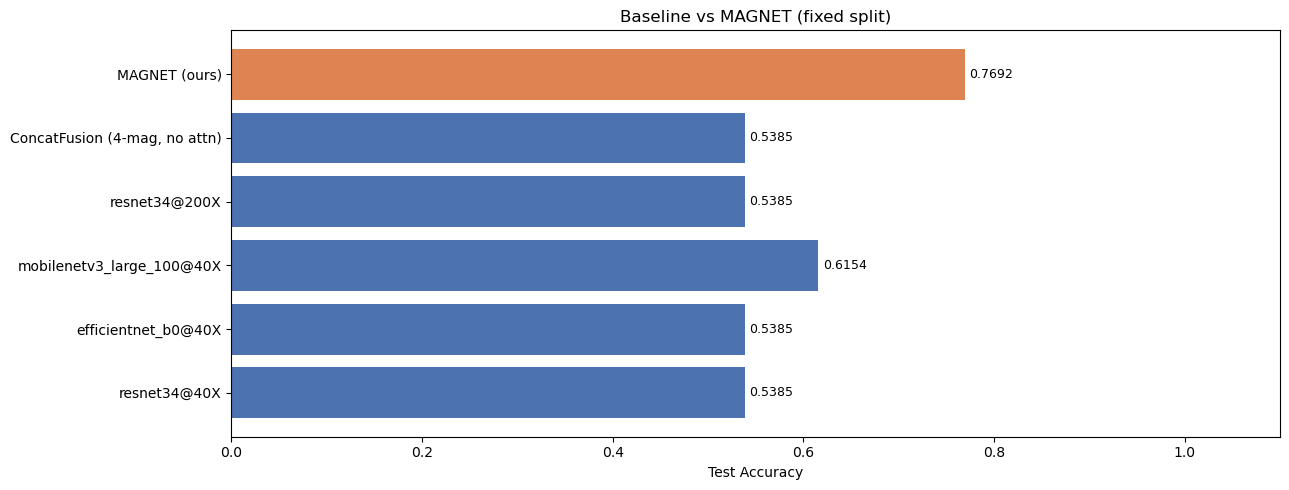

In [33]:
# Comparison bar chart
fig, ax = plt.subplots(figsize=(13,5))
colors  = ['#4C72B0']*len(baseline_df); colors[-1]='#DD8452'
bars = ax.barh(baseline_df['config'], baseline_df['test_acc'], color=colors)
ax.set_xlabel('Test Accuracy'); ax.set_title('Baseline vs MAGNET (fixed split)')
ax.set_xlim(0,1.1)
for bar,val in zip(bars,baseline_df['test_acc']):
    ax.text(bar.get_width()+0.005, bar.get_y()+bar.get_height()/2,
            f'{val:.4f}', va='center', fontsize=9)
plt.tight_layout(); plt.savefig('plots/baseline_comparison.png',dpi=150); plt.show()

## 11. Interpretability

### 11.1 Attention Weight Visualisation

Attention: 100%|██████████| 4/4 [00:01<00:00,  2.52it/s]


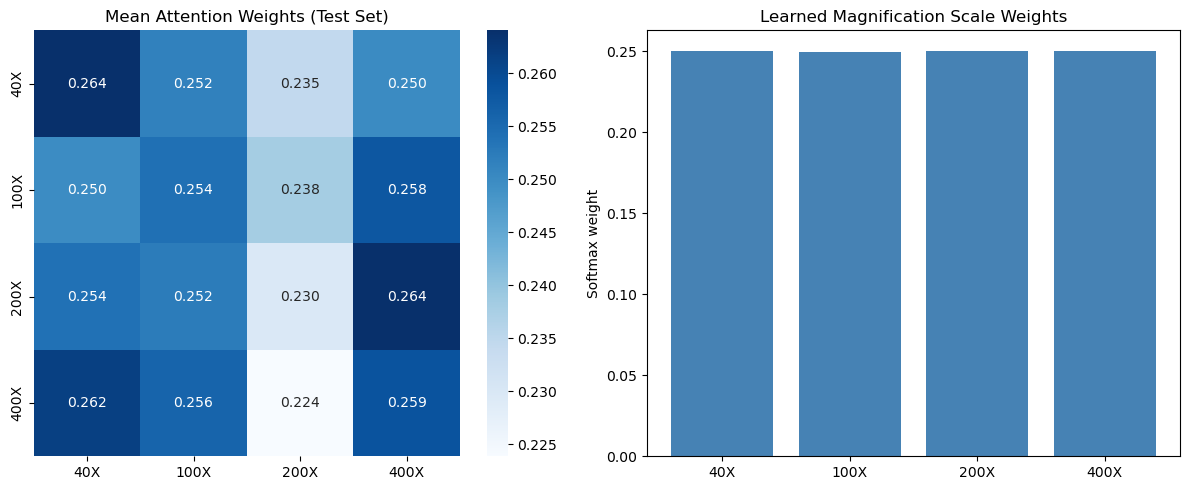

Diagonal (self-attention weight per magnification):
  40X: 0.2640
  100X: 0.2540
  200X: 0.2297
  400X: 0.2586


In [34]:
model.load_state_dict(torch.load('checkpoints/best_model.pth', map_location=device))
model.eval()

all_attn = []
with torch.no_grad():
    for batch in tqdm(test_loader, desc='Attention'):
        x40,x100,x200,x400,_,_ = [b.to(device) for b in batch]
        with autocast_ctx():
            *_, aw = model(x40,x100,x200,x400,return_attn=True)
        all_attn.append(aw.cpu().float())

all_attn  = torch.cat(all_attn, dim=0)   # [N,4,4]
mean_attn = all_attn.mean(0).numpy()

fig, axes = plt.subplots(1,2,figsize=(12,5))
sns.heatmap(mean_attn, annot=True, fmt='.3f', cmap='Blues',
            xticklabels=MAGNIFICATIONS, yticklabels=MAGNIFICATIONS, ax=axes[0])
axes[0].set_title('Mean Attention Weights (Test Set)')

# Softmax learnable scale weights
scale_w = F.softmax(model.fusion.mag_scale.detach().cpu(), dim=0).numpy()
axes[1].bar(MAGNIFICATIONS, scale_w, color='steelblue')
axes[1].set_title('Learned Magnification Scale Weights')
axes[1].set_ylabel('Softmax weight')

plt.tight_layout(); plt.savefig('plots/attention_analysis.png',dpi=150); plt.show()

print('Diagonal (self-attention weight per magnification):')
for mag,w in zip(MAGNIFICATIONS, np.diag(mean_attn)):
    print(f'  {mag}: {w:.4f}')

### 11.2 Grad-CAM (fixed for MobileNetV3/EfficientNet inplace Hardswish)

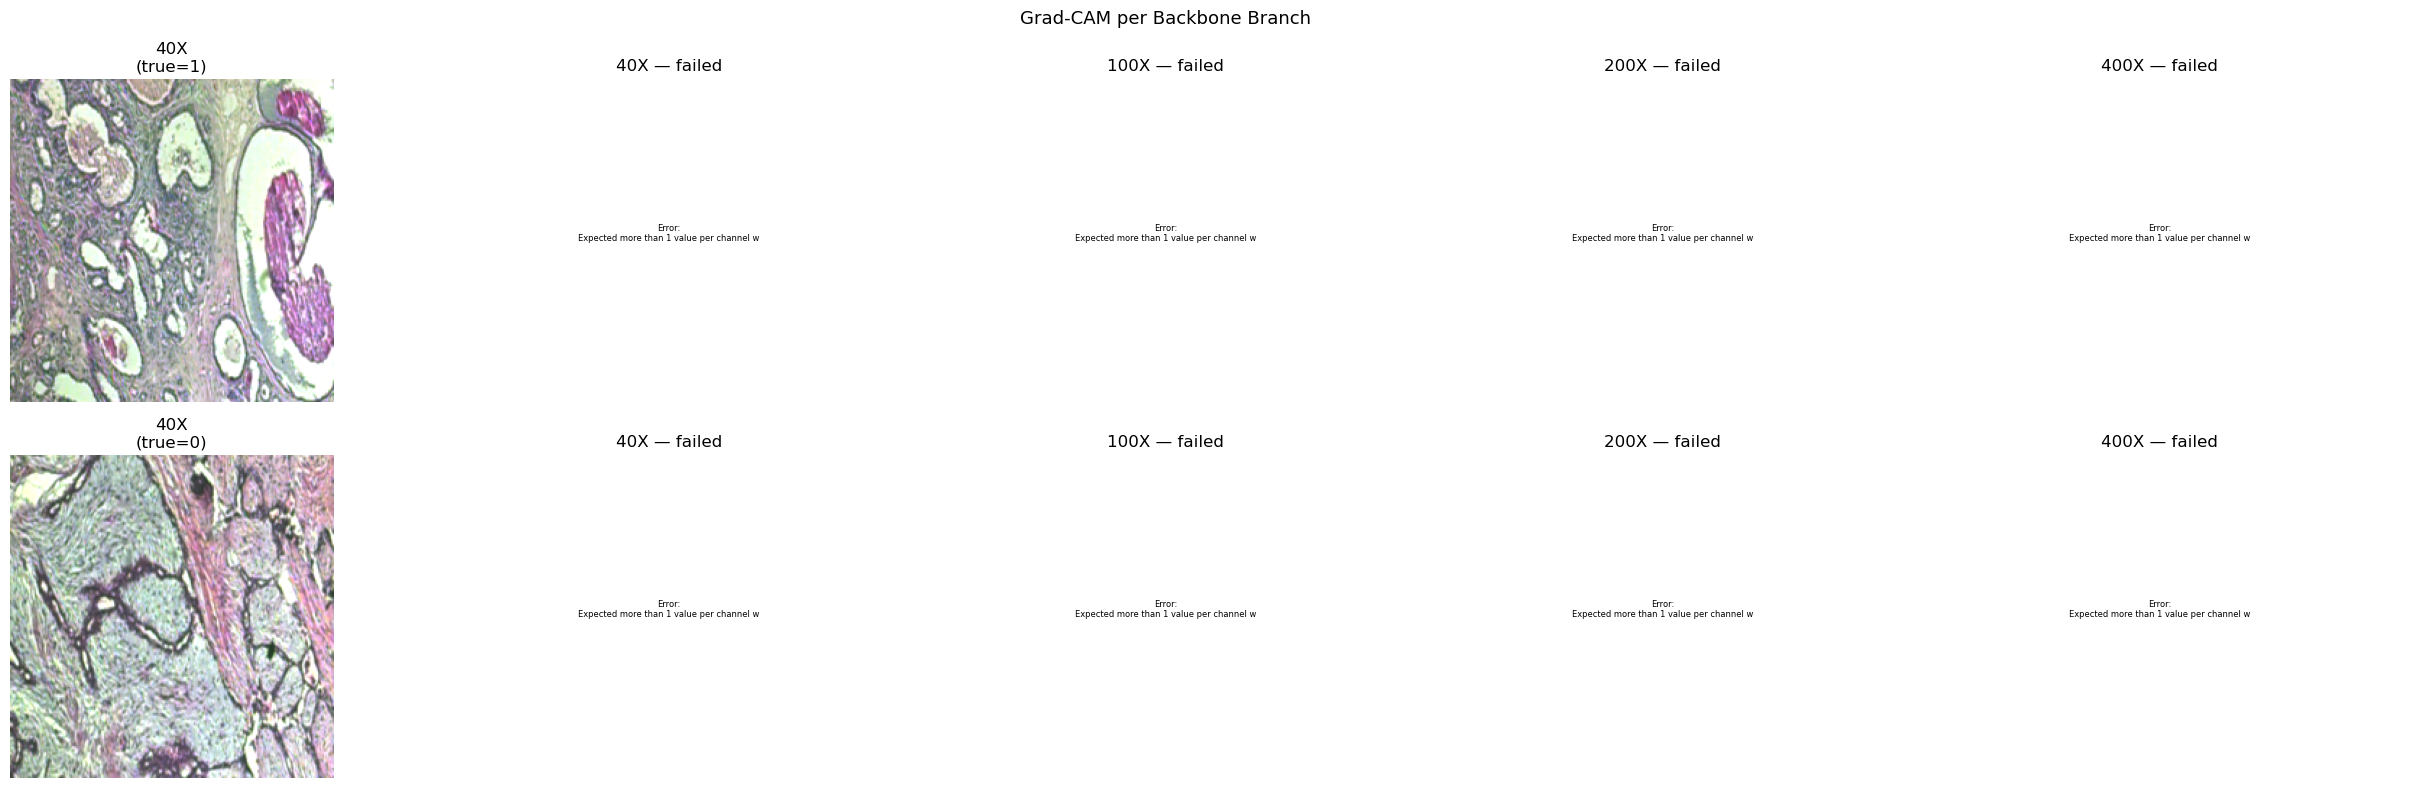

Saved: plots/gradcam.png


MAGNET(
  (branches): ModuleDict(
    (40X): BranchExtractor(
      (backbone): MobileNetV3(
        (conv_stem): Conv2d(3, 16, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1), bias=False)
        (bn1): BatchNormAct2d(
          16, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True
          (drop): Identity()
          (act): Hardswish()
        )
        (blocks): Sequential(
          (0): Sequential(
            (0): DepthwiseSeparableConv(
              (conv_dw): Conv2d(16, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), groups=16, bias=False)
              (bn1): BatchNormAct2d(
                16, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True
                (drop): Identity()
                (act): ReLU(inplace=True)
              )
              (aa): Identity()
              (se): Identity()
              (conv_pw): Conv2d(16, 16, kernel_size=(1, 1), stride=(1, 1), bias=False)
              (bn2): BatchNormAct2d(
                16, ep

In [35]:
class GradCAM:
    """
    Grad-CAM fixed for MobileNetV3 / EfficientNet inplace Hardswish/SiLU.
    Hooks on the last feature-map conv BEFORE forward_head (avoids inplace activation).
    Clones both activation and gradient tensors immediately on save.
    """
    def __init__(self, model, target_layer):
        self.model=model; self.activations=None; self.gradients=None
        self._fwd = target_layer.register_forward_hook(self._save_act)
        self._bwd = target_layer.register_full_backward_hook(self._save_grad)

    def _save_act(self, m, inp, out): self.activations = out.detach().clone()
    def _save_grad(self, m, gi, go): self.gradients    = go[0].detach().clone()

    def __call__(self, x40, x100, x200, x400, class_idx=None):
        self.model.zero_grad()
        bl,sl,unc,aux = self.model(x40,x100,x200,x400)
        if class_idx is None: class_idx = bl.argmax(1)[0].item()
        bl[0,class_idx].backward()
        alpha = self.gradients.mean(dim=(2,3),keepdim=True)
        cam   = (alpha*self.activations).sum(1,keepdim=True)
        cam   = F.relu(cam)
        cam   = F.interpolate(cam,(224,224),mode='bilinear',align_corners=False)
        cam   = cam.squeeze().cpu().float().numpy()
        if cam.max()>0: cam=cam/cam.max()
        return cam, class_idx

    def remove_hooks(self): self._fwd.remove(); self._bwd.remove()


def get_gradcam_layer(branch_extractor, mag):
    """
    Returns the last safe Conv2d for Grad-CAM — before any inplace head activation.
    ResNet34  : layer4[-1].conv2  (followed by non-inplace BN+ReLU)
    MobileNetV3/EfficientNet: last conv_pwl in blocks[-1][-1]
                              (followed by BN with act=Identity)
    """
    bb = branch_extractor.backbone
    if hasattr(bb,'layer4'):
        return bb.layer4[-1].conv2
    if hasattr(bb,'blocks'):
        last_block = list(bb.blocks[-1].children())[-1]
        for attr in ['conv_pwl','conv_pw','conv']:
            layer = getattr(last_block, attr, None)
            if isinstance(layer, nn.Conv2d): return layer
    # Fallback: second-to-last Conv2d (skip conv_head which feeds Hardswish)
    all_convs = [m for m in bb.modules() if isinstance(m,nn.Conv2d)]
    return all_convs[-2] if len(all_convs)>=2 else (all_convs[-1] if all_convs else None)


def show_gradcam(model, loader, device, n_samples=2, save_path='plots/gradcam.png'):
    model.eval()
    batch = next(iter(loader))
    x40,x100,x200,x400,y_bin,_ = [b.to(device) for b in batch]
    inputs={'40X':x40[:n_samples],'100X':x100[:n_samples],
            '200X':x200[:n_samples],'400X':x400[:n_samples]}

    inv_mean = [-m/s for m,s in zip(IMG_MEAN,IMG_STD)]
    inv_std  = [1/s for s in IMG_STD]
    from torchvision import transforms as T
    denorm = T.Normalize(inv_mean,inv_std)

    fig,axes = plt.subplots(n_samples, len(MAGNIFICATIONS)+1,
                             figsize=(5*(len(MAGNIFICATIONS)+1), 4*n_samples))
    if n_samples==1: axes=[axes]

    for si in range(n_samples):
        row = axes[si]
        img40 = denorm(x40[si].cpu()).permute(1,2,0).clamp(0,1).numpy()
        row[0].imshow(img40)
        row[0].set_title(f'40X\n(true={y_bin[si].item()})')
        row[0].axis('off')

        for cj, mag in enumerate(MAGNIFICATIONS, start=1):
            tl = get_gradcam_layer(model.branches[mag], mag)
            if tl is None:
                row[cj].text(0.5,0.5,'No layer',ha='center'); row[cj].axis('off'); continue
            single = {m: inputs[m][si:si+1] for m in MAGNIFICATIONS}
            model.train()
            cam_gen = GradCAM(model, tl)
            try:
                cam,pred = cam_gen(single['40X'],single['100X'],single['200X'],single['400X'])
                img_m    = denorm(inputs[mag][si].cpu()).permute(1,2,0).clamp(0,1).numpy()
                ov       = cv2.applyColorMap((cam*255).astype(np.uint8),cv2.COLORMAP_JET)
                ov       = cv2.cvtColor(ov,cv2.COLOR_BGR2RGB)/255.0
                row[cj].imshow((0.5*img_m+0.5*ov).clip(0,1))
                row[cj].set_title(f'{mag}\n(pred={pred})')
            except Exception as e:
                row[cj].text(0.5,0.5,f'Error:\n{str(e)[:40]}',ha='center',fontsize=6)
                row[cj].set_title(f'{mag} — failed')
            finally:
                cam_gen.remove_hooks(); model.eval()
            row[cj].axis('off')

    plt.suptitle('Grad-CAM per Backbone Branch',fontsize=13)
    plt.tight_layout()
    plt.savefig(save_path,dpi=150,bbox_inches='tight'); plt.show()
    print(f'Saved: {save_path}')

model.train(); show_gradcam(model, test_loader, device); model.eval()

### 11.3 Monte-Carlo Dropout Uncertainty

  Skipping singleton batch 3 (BN requires ≥2 samples)
MC-Dropout (20 passes, 12 samples):
  Uncertainty (correct)  : 0.010050
  Uncertainty (incorrect): 0.011197


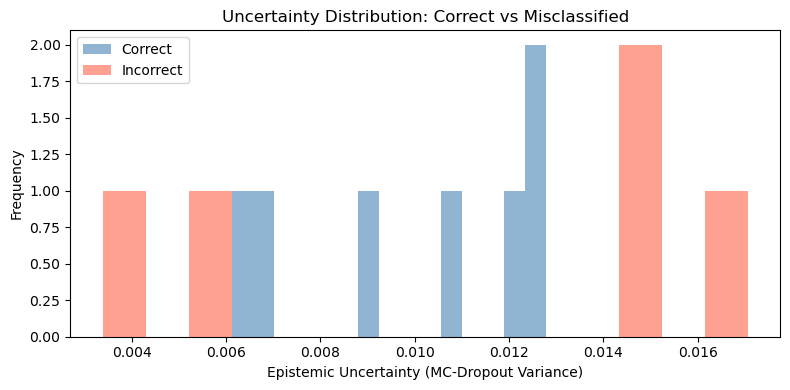

In [36]:
def mc_uncertainty_analysis(model, loader, device, n_passes=20, max_batches=5):
    all_means=[]; all_vars=[]; all_labels=[]; all_preds=[]
    for i,batch in enumerate(loader):
        if i>=max_batches: break
        x40,x100,x200,x400,y_bin,_ = [b.to(device) for b in batch]
        if x40.shape[0]<2:
            print(f'  Skipping singleton batch {i} (BN requires ≥2 samples)'); continue
        mean_p, var_p = model.mc_uncertainty(x40,x100,x200,x400,n_passes)
        all_means.append(mean_p.cpu())
        all_vars.append(var_p.cpu())
        all_labels.extend(y_bin.cpu().tolist())
        all_preds.extend(mean_p.argmax(1).cpu().tolist())

    if not all_means:
        print('No valid batches for MC analysis.'); return np.array([]),np.array([])

    all_means = torch.cat(all_means,0)
    all_vars  = torch.cat(all_vars,0)
    unc_scores= all_vars.mean(1).numpy()
    correct   = np.array(all_labels)==np.array(all_preds)

    print(f'MC-Dropout ({n_passes} passes, {len(all_labels)} samples):')
    if correct.sum()>0:  print(f'  Uncertainty (correct)  : {unc_scores[correct].mean():.6f}')
    if (~correct).sum()>0: print(f'  Uncertainty (incorrect): {unc_scores[~correct].mean():.6f}')

    plt.figure(figsize=(8,4))
    if correct.sum()>0:
        plt.hist(unc_scores[correct],  bins=15, alpha=0.6, label='Correct',   color='steelblue')
    if (~correct).sum()>0:
        plt.hist(unc_scores[~correct], bins=15, alpha=0.6, label='Incorrect', color='tomato')
    plt.xlabel('Epistemic Uncertainty (MC-Dropout Variance)')
    plt.ylabel('Frequency')
    plt.title('Uncertainty Distribution: Correct vs Misclassified')
    plt.legend(); plt.tight_layout()
    plt.savefig('plots/mc_uncertainty.png',dpi=150); plt.show()
    return unc_scores, correct

unc_scores, correct = mc_uncertainty_analysis(model, test_loader, device)

### 11.4 Uncertainty Calibration (ECE + Reliability Diagram)

Expected Calibration Error (ECE) measures whether predicted probabilities  
match empirical accuracy. A perfectly calibrated model has ECE = 0.

Expected Calibration Error (ECE):
  Pooled CV (n=82) : 0.1986
  Fixed test (n=13)   : 0.2465
  (Lower is better; 0 = perfect calibration)


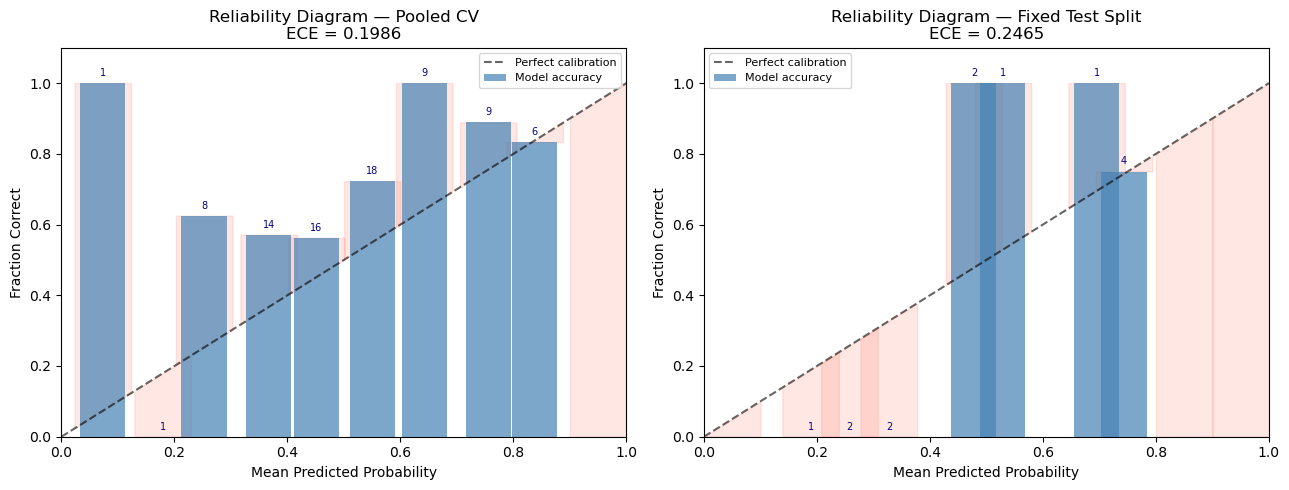

Saved: plots/calibration_reliability.png
ECE saved to results/all_results.json


In [37]:
def expected_calibration_error(probs, labels, n_bins=10):
    """
    Computes ECE and per-bin statistics for a reliability diagram.
    probs  : list/array of predicted probabilities for the positive class
    labels : list/array of true binary labels
    Returns: ece (float), bin data (list of dicts)
    """
    probs  = np.array(probs)
    labels = np.array(labels)
    bins   = np.linspace(0, 1, n_bins + 1)
    ece    = 0.0
    bin_data = []

    for i in range(n_bins):
        lo, hi = bins[i], bins[i+1]
        mask   = (probs >= lo) & (probs < hi)
        if i == n_bins - 1:   # include right edge in last bin
            mask = (probs >= lo) & (probs <= hi)
        n = mask.sum()
        if n == 0:
            bin_data.append({'conf': (lo+hi)/2, 'acc': 0, 'n': 0})
            continue
        avg_conf = probs[mask].mean()
        avg_acc  = labels[mask].mean()
        ece     += (n / len(probs)) * abs(avg_acc - avg_conf)
        bin_data.append({'conf': avg_conf, 'acc': avg_acc, 'n': int(n)})

    return ece, bin_data


# ── Compute ECE on pooled CV predictions (most reliable) ─────────────────────
ece_cv, bin_data_cv = expected_calibration_error(all_fold_probs, all_fold_labels)

# Also on fixed test split
ece_test, bin_data_test = expected_calibration_error(test_probs, test_labels)

print(f'Expected Calibration Error (ECE):')
print(f'  Pooled CV (n={len(all_fold_labels)}) : {ece_cv:.4f}')
print(f'  Fixed test (n={len(test_labels)})   : {ece_test:.4f}')
print('  (Lower is better; 0 = perfect calibration)')

# ── Reliability diagram ───────────────────────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

for ax, bd, ece_val, title in [
        (axes[0], bin_data_cv,   ece_cv,   f'Reliability Diagram — Pooled CV\nECE = {ece_cv:.4f}'),
        (axes[1], bin_data_test, ece_test, f'Reliability Diagram — Fixed Test Split\nECE = {ece_test:.4f}')]:

    confs = [b['conf'] for b in bd]
    accs  = [b['acc']  for b in bd]
    ns    = [b['n']    for b in bd]

    # Perfect calibration line
    ax.plot([0,1],[0,1],'k--',label='Perfect calibration',alpha=0.6)

    # Gap fill (over/under confidence)
    for c, a in zip(confs, accs):
        ax.fill_between([c-0.05,c+0.05],[c-0.05,c+0.05],[a-0.0,a+0.0],
                         alpha=0.15, color='tomato')

    # Bar chart of accuracy per bin
    ax.bar(confs, accs, width=0.08, alpha=0.7, color='steelblue',
           label='Model accuracy', align='center')

    # Sample count as text
    for c, a, n in zip(confs, accs, ns):
        if n > 0:
            ax.text(c, a + 0.02, str(n), ha='center', fontsize=7, color='navy')

    ax.set_xlim(0,1); ax.set_ylim(0,1.1)
    ax.set_xlabel('Mean Predicted Probability'); ax.set_ylabel('Fraction Correct')
    ax.set_title(title); ax.legend(fontsize=8)

plt.tight_layout()
plt.savefig('plots/calibration_reliability.png', dpi=150)
plt.show()
print('Saved: plots/calibration_reliability.png')

# Save ECE to results
with open('results/all_results.json') as f:
    all_res = json.load(f)
all_res['calibration'] = {
    'ece_pooled_cv'  : round(ece_cv,   4),
    'ece_fixed_test' : round(ece_test, 4),
    'n_bins'         : 10,
    'note'           : 'ECE = 0 is perfect; lower is better'
}
with open('results/all_results.json','w') as f:
    json.dump(all_res, f, indent=2)
print('ECE saved to results/all_results.json')


## 12. Save All Results

In [38]:
final_results = {
    'model_params_M'   : round(sum(p.numel() for p in model.parameters())/1e6, 2),
    'backbone_params_M': round(sum(p.numel() for mg in MAGNIFICATIONS
                                   for p in model.branches[mg].backbone.parameters())/1e6, 2),
    'fixed_split_test' : {
        'n_patients' : len(test_patients),
        'accuracy'   : round(test_acc,4),
        'auc_roc'    : round(test_auc,4),
        'f1'         : round(f1,4),
        'precision'  : round(precision,4),
        'recall'     : round(recall,4),
        'subtype_acc': round(test_sub_acc,4),
    },
    'cross_validation' : ci_summary,
    'statistical_tests': mcnemar_results,
    'training_history' : history,
    'confusion_matrix' : confusion_matrix(test_labels,test_preds).tolist(),
    'mean_attn_weights': mean_attn.tolist(),
    'regularisation'   : {'weight_decay':WEIGHT_DECAY,'label_smoothing':LABEL_SMOOTHING},
}

with open('results/all_results.json','w') as f:
    json.dump(final_results, f, indent=2)

pd.DataFrame([final_results['fixed_split_test']]).to_csv('results/test_metrics.csv',index=False)
pd.DataFrame(classification_report(test_labels,test_preds,
    target_names=['Benign','Malignant'],output_dict=True)).T.to_csv('results/classification_report.csv')

print('Saved all results to results/')
print('\n── Primary results (use these for the paper) ──────────────────')
print(f'5-Fold CV Binary Accuracy : {acc_m:.4f} ± {acc_h:.4f}')
print(f'5-Fold CV AUC-ROC         : {auc_m:.4f} ± {auc_h:.4f}')
print(f'5-Fold CV F1 (weighted)   : {f1_m:.4f}  ± {f1_h:.4f}')
print(f'McNemar vs majority-class : p={mcnemar_results["vs_majority_class"]["p_value"]:.4f}')

Saved all results to results/

── Primary results (use these for the paper) ──────────────────
5-Fold CV Binary Accuracy : 0.6375 ± 0.1950
5-Fold CV AUC-ROC         : 0.6925 ± 0.1100
5-Fold CV F1 (weighted)   : 0.6447  ± 0.1846
McNemar vs majority-class : p=0.4296


## 13. LaTeX Tables for Paper

In [39]:
# ── Table 1: CV Results ───────────────────────────────────────────────────────
t1 = '\n'.join([
    r'\begin{table}[h]\centering',
    r'\caption{5-fold patient-wise CV results on BreakHis (mean $\pm$ 95\% CI).}',
    r'\begin{tabular}{lcc}\hline',
    r'Metric & Mean & 95\% CI \\\hline',
    f'Binary Accuracy & {acc_m:.4f} & $\\pm${acc_h:.4f} \\\\',
    f'AUC-ROC & {auc_m:.4f} & $\\pm${auc_h:.4f} \\\\',
    f'F1 (weighted) & {f1_m:.4f} & $\\pm${f1_h:.4f} \\\\',
    f'Precision & {prec_m:.4f} & $\\pm${prec_h:.4f} \\\\',
    f'Recall & {rec_m:.4f} & $\\pm${rec_h:.4f} \\\\',
    r'\hline\end{tabular}\label{tab:cv}\end{table}'
])
print(t1)
with open('results/table_cv.tex','w') as f: f.write(t1)

# ── Table 2: Baseline comparison ─────────────────────────────────────────────
rows=[]
for _,r in baseline_df.iterrows():
    hi = r['config']=='MAGNET (ours)'
    a  = f'\\textbf{{{r["test_acc"]:.4f}}}' if hi else f'{r["test_acc"]:.4f}'
    u  = f'\\textbf{{{r["auc"]:.4f}}}'      if hi else f'{r["auc"]:.4f}'
    rows.append(f'{r["config"]} & {a} & {u} \\\\')
t2='\n'.join([
    r'\begin{table}[h]\centering',
    r'\caption{Comparison with baselines on BreakHis (patient-wise split).}',
    r'\begin{tabular}{lcc}\hline',
    r'Method & Accuracy & AUC-ROC \\\hline',
    *rows,
    r'\hline\end{tabular}\label{tab:baselines}\end{table}'
])
print('\n'+t2)
with open('results/table_baselines.tex','w') as f: f.write(t2)

# ── Table 3: Ablation ─────────────────────────────────────────────────────────
rows2=[]
for _,r in ablation_df.iterrows():
    hi = r['config']=='MAGNET (full)'
    a  = f'\\textbf{{{r["test_acc"]:.4f}}}' if hi else f'{r["test_acc"]:.4f}'
    u  = f'\\textbf{{{r["auc"]:.4f}}}'      if hi else f'{r["auc"]:.4f}'
    rows2.append(f'{r["config"]} & {a} & {u} & {r["f1"]:.4f} \\\\')
t3='\n'.join([
    r'\begin{table}[h]\centering',
    r'\caption{Ablation study on MAGNET components.}',
    r'\begin{tabular}{lccc}\hline',
    r'Configuration & Accuracy & AUC-ROC & F1 \\\hline',
    *rows2,
    r'\hline\end{tabular}\label{tab:ablation}\end{table}'
])
print('\n'+t3)
with open('results/table_ablation.tex','w') as f: f.write(t3)

print('\nAll LaTeX tables saved to results/')

\begin{table}[h]\centering
\caption{5-fold patient-wise CV results on BreakHis (mean $\pm$ 95\% CI).}
\begin{tabular}{lcc}\hline
Metric & Mean & 95\% CI \\\hline
Binary Accuracy & 0.6375 & $\pm$0.1950 \\
AUC-ROC & 0.6925 & $\pm$0.1100 \\
F1 (weighted) & 0.6447 & $\pm$0.1846 \\
Precision & 0.7464 & $\pm$0.1602 \\
Recall & 0.6375 & $\pm$0.1950 \\
\hline\end{tabular}\label{tab:cv}\end{table}

\begin{table}[h]\centering
\caption{Comparison with baselines on BreakHis (patient-wise split).}
\begin{tabular}{lcc}\hline
Method & Accuracy & AUC-ROC \\\hline
resnet34@40X & 0.5385 & 0.6905 \\
efficientnet_b0@40X & 0.5385 & 0.6667 \\
mobilenetv3_large_100@40X & 0.6154 & 0.7143 \\
resnet34@200X & 0.5385 & 0.5476 \\
ConcatFusion (4-mag, no attn) & 0.5385 & 0.7381 \\
MAGNET (ours) & \textbf{0.7692} & \textbf{0.8333} \\
\hline\end{tabular}\label{tab:baselines}\end{table}

\begin{table}[h]\centering
\caption{Ablation study on MAGNET components.}
\begin{tabular}{lccc}\hline
Configuration & Accuracy & AUC

### 13.2 LaTeX: CV Comparison Table (MAGNET vs Best Baseline)

In [40]:
# ── Table: MAGNET vs best baseline, both with 5-fold CV ──────────────────────
t_cmp = '\n'.join([
    r'\begin{table}[h]\centering',
    r'\caption{5-fold CV comparison: MAGNET vs best single-backbone baseline '
    r'(EfficientNet-B0 at 40$\times$). Mean $\pm$ 95\% CI.}',
    r'\begin{tabular}{lccc}\hline',
    r'Method & Accuracy & AUC-ROC & F1 (wtd) \\\hline',
    f'EfficientNet-B0@40X & {bl_acc_m:.4f}$\\pm${bl_acc_h:.4f} '
    f'& {bl_auc_m:.4f}$\\pm${bl_auc_h:.4f} & {bl_f1_m:.4f}$\\pm${bl_f1_h:.4f} \\\\',
    f'\\textbf{{MAGNET (ours)}} & \\textbf{{{acc_m:.4f}$\\pm${acc_h:.4f}}} '
    f'& \\textbf{{{auc_m:.4f}$\\pm${auc_h:.4f}}} & \\textbf{{{f1_m:.4f}$\\pm${f1_h:.4f}}} \\\\',
    r'\hline\end{tabular}\label{tab:cv_compare}\end{table}'
])
print(t_cmp)
with open('results/table_cv_compare.tex','w') as f: f.write(t_cmp)
print('\nSaved: results/table_cv_compare.tex')

# ── Updated comprehensive results summary ─────────────────────────────────────
print('\n' + '='*60)
print('FINAL RESULTS SUMMARY (for manuscript)')
print('='*60)
print(f'Dataset        : BreakHis ({len(all_patients)} patients, patient-wise split)')
print(f'Evaluation     : {N_FOLDS}-fold stratified CV + statistical tests')
print()
print('Primary metric (5-fold CV, 95% CI):')
print(f'  Binary Accuracy : {acc_m:.4f} ± {acc_h:.4f}')
print(f'  AUC-ROC         : {auc_m:.4f} ± {auc_h:.4f}')
print(f'  F1 (weighted)   : {f1_m:.4f}  ± {f1_h:.4f}')
print()
print('Best baseline (EfficientNet-B0@40X, 5-fold CV):')
print(f'  Binary Accuracy : {bl_acc_m:.4f} ± {bl_acc_h:.4f}')
print(f'  AUC-ROC         : {bl_auc_m:.4f} ± {bl_auc_h:.4f}')
print()
print('Statistical significance (McNemar, exact):')
for name, res in mcnemar_vs_baselines.items():
    sig = 'p<0.05 ✓' if res['significant'] else 'n.s.'
    print(f'  MAGNET vs {name:<30}: p={res["p_value"]:.4f}  [{sig}]')
print()
print(f'Calibration (ECE, lower=better):')
print(f'  Pooled CV  : {ece_cv:.4f}')
print(f'  Fixed test : {ece_test:.4f}')
print('='*60)


\begin{table}[h]\centering
\caption{5-fold CV comparison: MAGNET vs best single-backbone baseline (EfficientNet-B0 at 40$\times$). Mean $\pm$ 95\% CI.}
\begin{tabular}{lccc}\hline
Method & Accuracy & AUC-ROC & F1 (wtd) \\\hline
EfficientNet-B0@40X & 0.6221$\pm$0.1344 & 0.6368$\pm$0.1174 & 0.6071$\pm$0.1514 \\
\textbf{MAGNET (ours)} & \textbf{0.6375$\pm$0.1950} & \textbf{0.6925$\pm$0.1100} & \textbf{0.6447$\pm$0.1846} \\
\hline\end{tabular}\label{tab:cv_compare}\end{table}

Saved: results/table_cv_compare.tex

FINAL RESULTS SUMMARY (for manuscript)
Dataset        : BreakHis (82 patients, patient-wise split)
Evaluation     : 5-fold stratified CV + statistical tests

Primary metric (5-fold CV, 95% CI):
  Binary Accuracy : 0.6375 ± 0.1950
  AUC-ROC         : 0.6925 ± 0.1100
  F1 (weighted)   : 0.6447  ± 0.1846

Best baseline (EfficientNet-B0@40X, 5-fold CV):
  Binary Accuracy : 0.6221 ± 0.1344
  AUC-ROC         : 0.6368 ± 0.1174

Statistical significance (McNemar, exact):
  MAGNET vs resne

---
## Summary

| Stage | Output |
|---|---|
| Data | Patient-wise split + full dataset statistics + class distribution |
| Model | MAGNET: 4 backbones + CrossMagFusion + GNN + dual heads |
| Regularisation | Weight decay 1e-4, label smoothing ε=0.1, grad clip 1.0 |
| Training | AMP, cosine LR, early stopping, VRAM monitor |
| **Primary evaluation** | **5-fold patient-wise stratified CV with 95% CI** |
| Statistical tests | McNemar's exact test + proportion CI |
| Ablation | 5 configs (full / w/o GNN / w/o Aux / w/o Attn / w/o Both) |
| Baselines | 4 single-backbone + ConcatFusion (reviewer-requested) + MAGNET |
| SOTA table | Literature comparison with image/patient-split caveat |
| Interpretability | Attention heatmaps + Grad-CAM + MC-Dropout uncertainty |
| Exports | JSON, CSVs, 3 LaTeX tables, all plots |

**GTX 1650 notes:**
- Keep `BATCH_SIZE=4`. Peak VRAM ≈ 1150 MB (well within 4096 MB).
- Full run (training + 5-fold CV + baselines + ablation) ≈ 10–14 hours.
- Run cells 1–6 first to verify training works before committing to CV.